In [374]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.notebook import trange, tqdm
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
import scipy.io as sio
import pandas as pd
import numpy as np

import pandas as pd

In [375]:
g_column_names = [
    "B_vec", "L_vec", "TPU_R_mat", "MR_L_mat", "MR_R_mat", "TPU_th_mat", 
    "Tempo_3D", "Strain_3D", "Stress_3D", 
    "CoeffA_3D", "CoeffN_3D", "CoeffB_3D", "CoeffM_3D"]

# Carica il file di testo (rileva automaticamente i nomi delle colonne dalla prima riga)
df = pd.read_csv('Dataset_BH_distribution.txt', sep=r'\s+')
dg = pd.read_csv('Dataset_2D_Extended.txt', sep=r'\s+', header=None, names=g_column_names, index_col=False)


# 1. Estrai la lista dei nomi delle colonne in una variabile
column_names = df.columns.tolist()
column_names_dg = dg.columns.tolist()

print("Variabile column_names per df creata:")
print(column_names)

print("\nVariabile column_names_dg per dg creata:")
print(column_names_dg)

print("\nAnteprima dei dati caricati:")
print(df.tail(100))



Variabile column_names per df creata:
['B_magn_T', 'TPU_L_mm', 't_index', 't_val_s', 'x_coord_m', 'H_val_Am', 'B_val_T']

Variabile column_names_dg per dg creata:
['B_vec', 'L_vec', 'TPU_R_mat', 'MR_L_mat', 'MR_R_mat', 'TPU_th_mat', 'Tempo_3D', 'Strain_3D', 'Stress_3D', 'CoeffA_3D', 'CoeffN_3D', 'CoeffB_3D', 'CoeffM_3D']

Anteprima dei dati caricati:
        B_magn_T  TPU_L_mm  t_index  t_val_s  x_coord_m       H_val_Am  \
872540       1.2        40       97  0.04224   0.034056   11235.833619   
872541       1.2        40       97  0.04224   0.035629    9256.116355   
872542       1.2        40       97  0.04224   0.036923    6805.273151   
872543       1.2        40       97  0.04224   0.038000    3550.060193   
872544       1.2        40       98  0.04268   0.000000  117243.533350   
...          ...       ...      ...      ...        ...            ...   
872635       1.2        40      101  0.04400   0.032298   13144.772349   
872636       1.2        40      101  0.04400   0.034056

In [376]:
# original  dataset shape

print("Shape del dataset:", df.shape)

# extract the last column name
nome_ultima_colonna = df.columns[-1]

df_estratto = df[['B_magn_T','TPU_L_mm','t_index','x_coord_m' ,'H_val_Am',nome_ultima_colonna]]
dg_epsilon = dg[['B_vec','L_vec','Tempo_3D','Strain_3D']]
print("Shape del df dataset estratto:", df_estratto.shape)
print("Shape del dg dataset estratto:", dg_epsilon.shape)

Shape del dataset: (872640, 7)
Shape del df dataset estratto: (872640, 6)
Shape del dg dataset estratto: (42420, 4)


In [377]:
dg_epsilon

,B_vec,L_vec,Tempo_3D,Strain_3D
0,0.0,20,0.00000,1.210000e-12
1,0.0,20,0.00022,3.025000e-05
2,0.0,20,0.00044,1.210000e-04
3,0.0,20,0.00066,2.722500e-04
4,0.0,20,0.00088,4.840000e-04
...,...,...,...,...
42415,1.2,40,0.04224,5.030000e-02
42416,1.2,40,0.04268,5.085000e-02
42417,1.2,40,0.04312,5.140000e-02
42418,1.2,40,0.04356,5.195000e-02


In [378]:
# remove the rows where B_magn_T is zero

df_senza_zero = df_estratto[df_estratto['B_magn_T'] != 0]
dg_senza_zero = dg_epsilon[dg_epsilon['B_vec'] != 0]
print("Shape del df dataset estratto prima di rimuovere le righe con B_magn_T = 0:", df_estratto.shape)
print("Shape del df dataset dopo aver rimosso le righe con B_magn_T = 0:", df_senza_zero.shape)
df_senza_zero.head(20) 


Shape del df dataset estratto prima di rimuovere le righe con B_magn_T = 0: (872640, 6)
Shape del df dataset dopo aver rimosso le righe con B_magn_T = 0: (829008, 6)


,B_magn_T,TPU_L_mm,t_index,x_coord_m,H_val_Am,B_val_T
43632,0.063158,20,1,0.000000,5511.493005,0.046150
43633,0.063158,20,1,0.000533,8645.906537,0.074075
43634,0.063158,20,1,0.001180,10368.532991,0.089480
43635,0.063158,20,1,0.001965,10892.623336,0.094368
43636,0.063158,20,1,0.002917,10724.646635,0.092789
43637,0.063158,20,1,0.004072,9980.915596,0.086014
43638,0.063158,20,1,0.005403,8846.235362,0.075867
43639,0.063158,20,1,0.006767,7657.554481,0.065237
43640,0.063158,20,1,0.008133,6559.358767,0.055416
43641,0.063158,20,1,0.009500,5580.454105,0.046753


In [379]:
# extract the epsilon u need
dg_senza_zero.head(22)


,B_vec,L_vec,Tempo_3D,Strain_3D
2121,0.063158,20,0.00000,1.210000e-12
2122,0.063158,20,0.00022,3.025000e-05
2123,0.063158,20,0.00044,1.210000e-04
2124,0.063158,20,0.00066,2.722500e-04
2125,0.063158,20,0.00088,4.840000e-04
2126,0.063158,20,0.00110,7.562500e-04
2127,0.063158,20,0.00132,1.089000e-03
2128,0.063158,20,0.00154,1.482250e-03
2129,0.063158,20,0.00176,1.936000e-03
2130,0.063158,20,0.00198,2.450250e-03


In [380]:
# 1. Assicuriamoci che il dataset sia ordinato correttamente prima per i parametri fissi e poi per il tempo crescente
dg_senza_zero = dg_senza_zero.sort_values(by=['B_vec', 'L_vec', 'Tempo_3D'])

# 2. Creiamo il flag intero progressivo per il tempo. 
# Usiamo groupby per fare in modo che se cambiano B_vec o L_vec, il conteggio possa eventualmente ripartire o essere coerente.
dg_senza_zero['t_index'] = dg_senza_zero.groupby(['B_vec', 'L_vec'])['Tempo_3D'].ngroup()

# 3. Poiché .ngroup() parte da 0 (quindi 0.00000 -> 0, 0.00022 -> 1, ecc.), 
# aggiungiamo + 1 per farlo iniziare da 1 come hai chiesto tu (0.00000 -> 1, 0.00022 -> 2)
dg_senza_zero['t_index'] = dg_senza_zero['t_index'] + 1

# Visualizziamo il risultato con la nuova colonna inclusa
dg_senza_zero[['B_vec', 'L_vec', 'Tempo_3D', 't_index', 'Strain_3D']].head(22)

,B_vec,L_vec,Tempo_3D,t_index,Strain_3D
2121,0.063158,20,0.00000,1,1.210000e-12
2122,0.063158,20,0.00022,1,3.025000e-05
2123,0.063158,20,0.00044,1,1.210000e-04
2124,0.063158,20,0.00066,1,2.722500e-04
2125,0.063158,20,0.00088,1,4.840000e-04
2126,0.063158,20,0.00110,1,7.562500e-04
2127,0.063158,20,0.00132,1,1.089000e-03
2128,0.063158,20,0.00154,1,1.482250e-03
2129,0.063158,20,0.00176,1,1.936000e-03
2130,0.063158,20,0.00198,1,2.450250e-03


In [381]:
# Conta la riga progressiva ALL'INTERNO di ogni gruppo di B e L
dg_senza_zero['t_index'] = dg_senza_zero.groupby(['B_vec', 'L_vec']).cumcount() + 1

# Visualizziamo il risultato
dg_senza_zero[['B_vec', 'L_vec', 'Tempo_3D', 't_index', 'Strain_3D']].head(22)

,B_vec,L_vec,Tempo_3D,t_index,Strain_3D
2121,0.063158,20,0.00000,1,1.210000e-12
2122,0.063158,20,0.00022,2,3.025000e-05
2123,0.063158,20,0.00044,3,1.210000e-04
2124,0.063158,20,0.00066,4,2.722500e-04
2125,0.063158,20,0.00088,5,4.840000e-04
2126,0.063158,20,0.00110,6,7.562500e-04
2127,0.063158,20,0.00132,7,1.089000e-03
2128,0.063158,20,0.00154,8,1.482250e-03
2129,0.063158,20,0.00176,9,1.936000e-03
2130,0.063158,20,0.00198,10,2.450250e-03


In [382]:
import pandas as pd
import numpy as np

# ... il tuo codice precedente ...
df_senza_zero = df_estratto[df_estratto['B_magn_T'] != 0].copy() # Usiamo .copy() per evitare il SettingWithCopyWarning

# =========================================================================
# AGGIUNTA DELLA COLONNA DH (Delta temporale di H a parità di coordinata x)
# =========================================================================

# Assicuriamoci che il dataset sia ordinato correttamente: 
# prima per configurazione/geometria, poi per coordinata spaziale, e infine per tempo.
df_senza_zero = df_senza_zero.sort_values(by=['B_magn_T', 'TPU_L_mm', 'x_coord_m', 't_index'])

# Raggruppiamo per 'B_magn_T', 'TPU_L_mm' e 'x_coord_m' (così isoliamo ogni singola posizione x)
# e applichiamo il metodo .diff() sulla colonna 'H_val_Am'
df_senza_zero['DH'] = df_senza_zero.groupby(['B_magn_T', 'TPU_L_mm', 'x_coord_m'])['H_val_Am'].diff()

# Gestione del primo istante temporale:
# Il primo istante di ogni coordinata non ha un istante precedente, quindi .diff() restituirà NaN.
# Possiamo impostarlo a 0 (nessuna variazione iniziale)
df_senza_zero['DH'] = df_senza_zero['DH'].fillna(0)
print(df_senza_zero.shape)
df_senza_zero[['B_magn_T', 'TPU_L_mm', 't_index', 'x_coord_m', 'H_val_Am', 'DH']].head(20)


(829008, 7)


,B_magn_T,TPU_L_mm,t_index,x_coord_m,H_val_Am,DH
43632,0.063158,20,1,0.0,5511.493005,0.000000
43651,0.063158,20,2,0.0,5511.466898,-0.026107
43670,0.063158,20,3,0.0,5511.460854,-0.006044
43689,0.063158,20,4,0.0,5511.499196,0.038342
43708,0.063158,20,5,0.0,5511.545560,0.046364
43727,0.063158,20,6,0.0,5511.581791,0.036231
43746,0.063158,20,7,0.0,5511.622474,0.040683
43765,0.063158,20,8,0.0,5511.680977,0.058503
43784,0.063158,20,9,0.0,5511.753677,0.072699
43803,0.063158,20,10,0.0,5511.832059,0.078382


In [383]:
import pandas as pd
import numpy as np

# 1. Filtriamo per eliminare gli zeri
df_senza_zero = df_estratto[df_estratto['B_magn_T'] != 0].copy()

# 2. Ordiniamo temporaneamente per fare il calcolo corretto di DH nel tempo
df_senza_zero = df_senza_zero.sort_values(by=['B_magn_T', 'TPU_L_mm', 'x_coord_m', 't_index'])

# 3. Calcoliamo DH (con il groupby sul tempo)
df_senza_zero['DH'] = df_senza_zero.groupby(['B_magn_T', 'TPU_L_mm', 'x_coord_m'])['H_val_Am'].diff()
df_senza_zero['DH'] = df_senza_zero['DH'].fillna(0)

# =========================================================================
# NUOVO ORDINAMENTO: ORIENTATO ALLO SPAZIO (Come nella tua nuova figura)
# =========================================================================
# Ordiniamo prima per B e L, poi per ISTANTE TEMPORALE, e infine per COORDINATA X crescente
df_senza_zero = df_senza_zero.sort_values(by=['B_magn_T', 'TPU_L_mm', 't_index', 'x_coord_m'])

# Visualizziamo il risultato con la colonna DH inclusa
print(df_senza_zero.shape)
df_senza_zero[['B_magn_T', 'TPU_L_mm', 't_index', 'x_coord_m', 'H_val_Am', 'B_val_T', 'DH']].head(20)

(829008, 7)


,B_magn_T,TPU_L_mm,t_index,x_coord_m,H_val_Am,B_val_T,DH
43632,0.063158,20,1,0.000000,5511.493005,0.046150,0.000000
43633,0.063158,20,1,0.000533,8645.906537,0.074075,0.000000
43634,0.063158,20,1,0.001180,10368.532991,0.089480,0.000000
43635,0.063158,20,1,0.001965,10892.623336,0.094368,0.000000
43636,0.063158,20,1,0.002917,10724.646635,0.092789,0.000000
43637,0.063158,20,1,0.004072,9980.915596,0.086014,0.000000
43638,0.063158,20,1,0.005403,8846.235362,0.075867,0.000000
43639,0.063158,20,1,0.006767,7657.554481,0.065237,0.000000
43640,0.063158,20,1,0.008133,6559.358767,0.055416,0.000000
43641,0.063158,20,1,0.009500,5580.454105,0.046753,0.000000


In [384]:
# Uniamo i due dataset facendo combaciare le triplette identificative
df_senza_zero = pd.merge(
    df_senza_zero, 
    dg_senza_zero[['B_vec', 'L_vec', 't_index', 'Strain_3D']],  # Prendiamo solo le colonne che servono da dg
    left_on=['B_magn_T', 'TPU_L_mm', 't_index'],                # Chiavi del primo dataset (df)
    right_on=['B_vec', 'L_vec', 't_index'],                     # Chiavi del secondo dataset (dg)
    how='left'                                                  # Mantiene tutte le righe di df intatte
)

# Poiché le colonne di aggancio di dg (B_vec e L_vec) verrebbero duplicate, 
# le cancelliamo per tenere il dataset pulito
df_senza_zero = df_senza_zero.drop(columns=['B_vec', 'L_vec'])


# Visualizziamo il risultato finale per verificare l'aggiunta di Strain_3D
df_senza_zero[['B_magn_T', 'TPU_L_mm', 't_index', 'x_coord_m', 'H_val_Am', 'DH', 'Strain_3D']].sample(20)

,B_magn_T,TPU_L_mm,t_index,x_coord_m,H_val_Am,DH,Strain_3D
629392,0.947368,29,64,0.019974,26650.450256,24.241375,0.032150
473498,0.694737,38,27,0.030556,8060.355247,9.776294,0.011800
810244,1.200000,32,74,0.004628,177365.027115,41.267074,0.037650
328001,0.505263,31,64,0.008381,46965.287006,23.337572,0.032150
122415,0.189474,37,40,0.024649,3751.481488,3.916555,0.018950
747685,1.136842,23,10,0.017195,37662.535603,32.519559,0.002450
423909,0.631579,35,65,0.029785,7613.028890,10.441748,0.032700
755353,1.136842,27,10,0.005670,151591.339732,42.580354,0.002450
775222,1.136842,36,67,0.014401,52673.413052,34.839714,0.033800
455390,0.694737,29,90,0.027550,3965.087924,4.449696,0.046450


In [385]:
# check
b_cercato = 0.315789
l_cercato = 25
t_cercato = 14
riga_specifica = dg_senza_zero[
    np.isclose(dg_senza_zero['B_vec'], b_cercato) & 
    (dg_senza_zero['L_vec'] == l_cercato) & 
    (dg_senza_zero['t_index'] == t_cercato)
]
# 3. Visualizza il risultato
riga_specifica[['B_vec', 'L_vec', 'Tempo_3D', 't_index', 'Strain_3D']]

,B_vec,L_vec,Tempo_3D,t_index,Strain_3D
11123,0.315789,25,0.003575,14,0.00465


In [386]:
# Visualizziamo il risultato finale per verificare l'aggiunta di Strain_3D
df_senza_zero['x_norm'] = df_senza_zero['x_coord_m'] / (df_senza_zero['TPU_L_mm'] * 1e-3)
df_senza_zero[['B_magn_T', 'TPU_L_mm', 't_index', 'x_coord_m', 'H_val_Am', 'DH', 'Strain_3D','x_norm']].head(20)

,B_magn_T,TPU_L_mm,t_index,x_coord_m,H_val_Am,DH,Strain_3D,x_norm
0,0.063158,20,1,0.000000,5511.493005,0.000000,1.210000e-12,0.000000
1,0.063158,20,1,0.000533,8645.906537,0.000000,1.210000e-12,0.026659
2,0.063158,20,1,0.001180,10368.532991,0.000000,1.210000e-12,0.059004
3,0.063158,20,1,0.001965,10892.623336,0.000000,1.210000e-12,0.098246
4,0.063158,20,1,0.002917,10724.646635,0.000000,1.210000e-12,0.145857
5,0.063158,20,1,0.004072,9980.915596,0.000000,1.210000e-12,0.203620
6,0.063158,20,1,0.005403,8846.235362,0.000000,1.210000e-12,0.270127
7,0.063158,20,1,0.006767,7657.554481,0.000000,1.210000e-12,0.338334
8,0.063158,20,1,0.008133,6559.358767,0.000000,1.210000e-12,0.406667
9,0.063158,20,1,0.009500,5580.454105,0.000000,1.210000e-12,0.475000


In [387]:
# reshape the dataset as follow:
# for a given L x_coord should range from 0 to its max considered the legnth u choose. to each x-coord for agiven  sould be H_val aside, aside to
# that it should be the DH associated to that coordinate. simply put:
'''
Hval(0); DH(0)
Hval(0.1); DH(0.1)
...
Hval(x_coord_max); DH(x_coord_max)

and i will have this kind of  block for every time step excluded the last one!


Unluckily, this NEW bigger block for every t will be TRUE for one specific L. i would also to do all these passages for every B!

'''

'\nHval(0); DH(0)\nHval(0.1); DH(0.1)\n...\nHval(x_coord_max); DH(x_coord_max)\n\nand i will have this kind of  block for every time step excluded the last one!\n\n\nUnluckily, this NEW bigger block for every t will be TRUE for one specific L. i would also to do all these passages for every B!\n\n'

In [388]:
df_senza_zero = df_senza_zero.sort_values(
    by=['B_magn_T', 'TPU_L_mm', 'x_coord_m', 't_index'])

df_senza_zero['H_prev'] = (
    df_senza_zero
    .groupby(['B_magn_T','TPU_L_mm','x_coord_m'])['H_val_Am']
    .shift(1)
)

df_senza_zero['H_prev'] = df_senza_zero['H_prev'].fillna(0)
#df_senza_zero = df_senza_zero.dropna(subset=['H_prev'])

In [389]:
# Gradiente spaziale di H_prev (approssimato)
df_senza_zero['dH_prev_dx'] = (
    df_senza_zero
    .groupby(['B_magn_T','TPU_L_mm','t_index'])['H_prev']
    .diff()
    .fillna(0)
)

In [390]:
df_senza_zero.iloc[0:120]

,B_magn_T,TPU_L_mm,t_index,x_coord_m,H_val_Am,B_val_T,DH,Strain_3D,x_norm,H_prev,dH_prev_dx
0,0.063158,20,1,0.000000,5511.493005,0.046150,0.000000,1.210000e-12,0.000000,0.000000,0.000000
19,0.063158,20,2,0.000000,5511.466898,0.046150,-0.026107,3.025000e-05,0.000000,5511.493005,0.000000
38,0.063158,20,3,0.000000,5511.460854,0.046148,-0.006044,1.210000e-04,0.000000,5511.466898,0.000000
57,0.063158,20,4,0.000000,5511.499196,0.046145,0.038342,2.722500e-04,0.000000,5511.460854,0.000000
76,0.063158,20,5,0.000000,5511.545560,0.046142,0.046364,4.840000e-04,0.000000,5511.499196,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
267,0.063158,20,15,0.000533,8666.473521,0.073882,2.186739,5.200000e-03,0.026659,8664.286782,3152.132394
286,0.063158,20,16,0.000533,8668.683408,0.073861,2.209887,5.750000e-03,0.026659,8666.473521,3154.244724
305,0.063158,20,17,0.000533,8670.900797,0.073841,2.217389,6.300000e-03,0.026659,8668.683408,3156.379021
324,0.063158,20,18,0.000533,8673.120202,0.073820,2.219405,6.850000e-03,0.026659,8670.900797,3158.521597


In [391]:
# Estrae i valori unici come un array NumPy
B_magn_vec = df_senza_zero['B_magn_T'].unique()
print(B_magn_vec)
L_vec = df_senza_zero['TPU_L_mm'].unique()
print(L_vec)
t_vec = df_senza_zero['t_index'].unique()
print(t_vec)

[0.06315789 0.12631579 0.18947368 0.25263158 0.31578947 0.37894737
 0.44210526 0.50526316 0.56842105 0.63157895 0.69473684 0.75789474
 0.82105263 0.88421053 0.94736842 1.01052632 1.07368421 1.13684211
 1.2       ]
[20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40]
[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100 101]


In [392]:
# Per ogni coppia (B, L), per ogni timestep t come TARGET:
# - Input: H(x) all'istante t=0 (o t=1, il primo non-zero) 
#          + Strain al timestep t
# - Output: H(x) al timestep t

records = []

for (B, L), gruppo in df_senza_zero.groupby(['B_magn_T', 'TPU_L_mm']):
    gruppo = gruppo.sort_values(['t_index', 'x_coord_m'])
    t_steps = sorted(gruppo['t_index'].unique())
    x_coords = sorted(gruppo['x_coord_m'].unique())
    
    # H iniziale (t=1, il primo istante)
    H_init = (gruppo[gruppo['t_index'] == t_steps[0]]
               .sort_values('x_coord_m')['H_val_Am'].values)
    
    # Per ogni istante target
    for t in t_steps[1:]:  # saltiamo il primo (è l'input)
        step = gruppo[gruppo['t_index'] == t].sort_values('x_coord_m')
        strain_t = step['Strain_3D'].values[0]  # Strain è uniforme in x per dato t
        H_target = step['H_val_Am'].values
        
        for i, x in enumerate(x_coords):
            records.append({
                'B_magn_T': B,
                'TPU_L_mm': L,
                'x_coord_m': x,
                'x_norm': x / (L * 1e-3),
                'Strain_target': strain_t,
                'H_init_at_x': H_init[i],      # H iniziale ALLA STESSA x
                'H_true': H_target[i]           # quello che la rete deve predire
            })

df_new = pd.DataFrame(records)

In [393]:
df_new.head(20)

,B_magn_T,TPU_L_mm,x_coord_m,x_norm,Strain_target,H_init_at_x,H_true
0,0.063158,20,0.000000,0.000000,0.000030,5511.493005,5511.466898
1,0.063158,20,0.000533,0.026659,0.000030,8645.906537,8645.878381
2,0.063158,20,0.001180,0.059004,0.000030,10368.532991,10368.550848
3,0.063158,20,0.001965,0.098246,0.000030,10892.623336,10892.684250
4,0.063158,20,0.002917,0.145857,0.000030,10724.646635,10724.921574
5,0.063158,20,0.004072,0.203620,0.000030,9980.915596,9980.814572
6,0.063158,20,0.005403,0.270127,0.000030,8846.235362,8846.207743
7,0.063158,20,0.006767,0.338334,0.000030,7657.554481,7657.537768
8,0.063158,20,0.008133,0.406667,0.000030,6559.358767,6559.351453
9,0.063158,20,0.009500,0.475000,0.000030,5580.454105,5580.430795


In [394]:
X = df_new[['B_magn_T','TPU_L_mm','x_coord_m','x_norm','Strain_target','H_init_at_x']]
y = df_new['H_true']

In [395]:
records = []

for (B, L), gruppo in df_new.groupby(['B_magn_T', 'TPU_L_mm']):
    gruppo = gruppo.sort_values(['Strain_target', 'x_coord_m'])
    t_steps = sorted(gruppo['Strain_target'].unique())
    x_coords = sorted(gruppo['x_coord_m'].unique())
    
    H_init = (gruppo[gruppo['Strain_target'] == t_steps[0]]
              .sort_values('x_coord_m')['H_true'].values)
    
    for t in t_steps[1:]:
        step = gruppo[gruppo['Strain_target'] == t].sort_values('x_coord_m')
        H_target = step['H_true'].values
        
        for i, x in enumerate(x_coords):
            delta = H_target[i] - H_init[i]
            records.append({
                'B_magn_T': B,
                'TPU_L_mm': L,
                'x_norm': x / (L * 1e-3),
                'Strain_target': t,
                'H_init_at_x': H_init[i],
                # Target: solo la variazione
                'dH': delta,
                # Opzionale: variazione normalizzata su H_init
                'dH_norm': delta / (np.abs(H_init[i]) + 1.0)
            })

In [396]:
records

[{'B_magn_T': np.float64(0.0631578947368421),
  'TPU_L_mm': np.int64(20),
  'x_norm': np.float64(0.0),
  'Strain_target': np.float64(0.000121),
  'H_init_at_x': np.float64(5511.46689809653),
  'dH': np.float64(-0.006044127029781521),
  'dH_norm': np.float64(-1.0964468615437082e-06)},
 {'B_magn_T': np.float64(0.0631578947368421),
  'TPU_L_mm': np.int64(20),
  'x_norm': np.float64(0.026659163069179998),
  'Strain_target': np.float64(0.000121),
  'H_init_at_x': np.float64(8645.8783811467),
  'dH': np.float64(0.23874813829934283),
  'dH_norm': np.float64(2.7610905089159055e-05)},
 {'B_magn_T': np.float64(0.0631578947368421),
  'TPU_L_mm': np.int64(20),
  'x_norm': np.float64(0.059003716857694996),
  'Strain_target': np.float64(0.000121),
  'H_init_at_x': np.float64(10368.5508483995),
  'dH': np.float64(0.4180218117999175),
  'dH_norm': np.float64(4.031243184119566e-05)},
 {'B_magn_T': np.float64(0.0631578947368421),
  'TPU_L_mm': np.int64(20),
  'x_norm': np.float64(0.098245889521575),
  '

In [397]:
from scipy.interpolate import interp1d
from scipy.interpolate import PchipInterpolator
import numpy as np

N_POINTS = 64  # griglia fissa, scegli tu

x_fixed = np.linspace(0, 1, N_POINTS)  # coordinate normalizzate 0→1

records = []

for (B, L), gruppo in df_new.groupby(['B_magn_T', 'TPU_L_mm']):
    t_steps = sorted(gruppo['Strain_target'].unique())
    
    # Curva iniziale interpolata su griglia fissa
    step0 = gruppo[gruppo['Strain_target'] == t_steps[0]].sort_values('x_coord_m')
    x0 = step0['x_norm'].values        # coordinate normalizzate 0→1
    H0 = step0['H_true'].values
    
    #interp0 = interp1d(x0, H0, kind='linear', fill_value='extrapolate')
    #H_init_fixed = interp0(x_fixed)    # ora ha sempre N_POINTS punti

    # PCHIP invece di interp1d lineare
    interp0      = PchipInterpolator(x0, H0)
    H_init_fixed = interp0(x_fixed)

    
    for t in t_steps[1:]:
        step = gruppo[gruppo['Strain_target'] == t].sort_values('x_coord_m')
        x_t = step['x_norm'].values
        H_t = step['H_true'].values
        
        #interp_t = interp1d(x_t, H_t, kind='linear', fill_value='extrapolate')
        #H_target_fixed = interp_t(x_fixed)

        interp_t       = PchipInterpolator(x_t, H_t)
        H_target_fixed = interp_t(x_fixed)
        
        records.append({
            'B_magn_T': B,
            'TPU_L_mm': L,
            'Strain_target': t,
            'H_init_curve': H_init_fixed,              # sempre (64,)
            'dH_curve': H_target_fixed - H_init_fixed, # sempre (64,)
        })

In [398]:
np.array(records).shape

(39501,)

In [399]:
df_curves = pd.DataFrame(records)
print(df_curves.shape)

(39501, 5)


In [400]:
from sklearn.model_selection import GroupShuffleSplit

# Chiave di gruppo: ogni coppia (B,L) intera va in un solo set
gruppi = (df_curves['B_magn_T'].astype(str) + '_' + 
          df_curves['TPU_L_mm'].astype(str))

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
trainval_idx, test_idx = next(gss1.split(df_curves, groups=gruppi))

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, val_idx = next(gss2.split(
    df_curves.iloc[trainval_idx], 
    groups=gruppi.iloc[trainval_idx]
))

df_train = df_curves.iloc[trainval_idx].iloc[train_idx]
df_val   = df_curves.iloc[trainval_idx].iloc[val_idx]
df_test  = df_curves.iloc[test_idx]

print(f"Train: {len(df_train)} curve")
print(f"Val:   {len(df_val)} curve")
print(f"Test:  {len(df_test)} curve")

Train: 23661 curve
Val:   7920 curve
Test:  7920 curve


In [401]:
import numpy as np

def build_tensors(df):
    X_scalar = df[['B_magn_T', 'TPU_L_mm', 'Strain_target']].values  # (N, 3)
    
    # Stack degli array H_init_curve: ogni cella è (64,)
    X_curve  = np.stack(df['H_init_curve'].values)   # (N, 64)
    y        = np.stack(df['dH_curve'].values)        # (N, 64)
    
    X = np.concatenate([X_scalar, X_curve], axis=1)  # (N, 67)
    return X, y

X_train, y_train = build_tensors(df_train)
X_val,   y_val   = build_tensors(df_val)
X_test,  y_test  = build_tensors(df_test)

print(X_train.shape, y_train.shape)  # (N_train, 67), (N_train, 64)

(23661, 67) (23661, 64)


In [402]:
from sklearn.preprocessing import MinMaxScaler

# Scala X e y separatamente
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_sc = scaler_X.fit_transform(X_train)
X_val_sc   = scaler_X.transform(X_val)
X_test_sc  = scaler_X.transform(X_test)

y_train_sc = scaler_y.fit_transform(y_train)
y_val_sc   = scaler_y.transform(y_val)
y_test_sc  = scaler_y.transform(y_test)

In [403]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Converti in tensori
X_train_tensor = torch.tensor(X_train_sc, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val_sc,   dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test_sc,  dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_sc, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val_sc,   dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test_sc,  dtype=torch.float32)

# Dataset e DataLoader — batch size più piccolo perché ogni campione è più grande
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor),
                          batch_size=32, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_tensor,   y_val_tensor),
                          batch_size=32, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_tensor,  y_test_tensor),
                          batch_size=32, shuffle=False)

In [404]:
class NN_H_predictor(nn.Module):
    def __init__(self, n_input, n_output, n_hidden1=256, n_hidden2=128):
        super().__init__()
        self.fc1 = nn.Linear(n_input, n_hidden1)
        self.fc2 = nn.Linear(n_hidden1, n_hidden2)
        self.fc3 = nn.Linear(n_hidden2, n_output)
        self.act = nn.LeakyReLU()
    
    def forward(self, x):
        x = self.act(self.fc1(x))
        x = self.act(self.fc2(x))
        return self.fc3(x)

N_POINTS = 64
n_input  = 3 + N_POINTS   # 67: (B, L, strain) + H_init intera
n_output = N_POINTS        # 64: dH su tutta la curva

model = NN_H_predictor(n_input, n_output)

In [405]:
loss_criterion = nn.MSELoss()
eta = 1e-3 # Learning Rate
optimizer = optim.Adam(model.parameters(), lr=eta)
n_epochs = 20

In [406]:
def train_model(model, train_data, loss_criterion, optimizer, loss_logger, epoch_idx):
  model.train()
  total_loss = 0
  for batch_idx, (data,target) in enumerate(tqdm(train_data, desc="Training", leave=False)):
    pred_output = model(data)
    loss = loss_criterion(pred_output, target)
    optimizer.zero_grad() # Clears all gradients; prevent gradient accumulation
    loss.backward() # Computes gradient of loss wrt model parameters
    optimizer.step() # Updates model paraments using computed gradients
    #loss_logger.append(loss.item()) # Logs the loss; convenient if batch_size = dataset_size
    # .item() - Converts tensor into a python number
    total_loss += loss.item() # Track/accumulate the loss

  avg_loss = total_loss / len(train_data) # Compute the average loss
  loss_logger.append(avg_loss) # Store the loss

  #print(f"Epoch: {epoch_idx} | Loss: {avg_loss:.4f}")


  return model, optimizer, loss_logger

In [407]:
def validate_model(model, val_data, loss_criterion, val_loss_logger):
    model.eval() # Set to evaluation mode
    total_loss = 0
    with torch.no_grad():
        for data, target in val_data:
            pred_output = model(data)
            loss = loss_criterion(pred_output, target)
            total_loss += loss.item()

    avg_loss = total_loss / len(val_data)
    val_loss_logger.append(avg_loss)
    return val_loss_logger

In [408]:
def test_model(model, test_data, loss_criterion, loss_logger):
  total_loss = 0
  with torch.no_grad():
    for batch_idx, (data,target) in enumerate(tqdm(test_data, desc="Testing", leave=False)):
      pred_output = model(data)
      loss = loss_criterion(pred_output, target)
      #loss_logger.append(loss.item())
      total_loss += loss.item()

    avg_loss = total_loss / len(test_data)
    loss_logger.append(avg_loss)

    return loss_logger

In [409]:
train_loss, val_loss, test_loss = [], [], []

for i in trange(n_epochs, desc="Epoch"):
    model, optimizer, train_loss = train_model(
        model, train_loader, loss_criterion, optimizer, train_loss, i)
    val_loss = validate_model(model, val_loader, loss_criterion, val_loss)

test_loss = test_model(model, test_loader, loss_criterion, test_loss)

Epoch:   0%|          | 0/20 [00:00<?, ?it/s]

Training:   0%|          | 0/740 [00:00<?, ?it/s]

Training:   0%|          | 0/740 [00:00<?, ?it/s]

Training:   0%|          | 0/740 [00:00<?, ?it/s]

Training:   0%|          | 0/740 [00:00<?, ?it/s]

Training:   0%|          | 0/740 [00:00<?, ?it/s]

... (12 outputs left out)

Training:   0%|          | 0/740 [00:00<?, ?it/s]

Training:   0%|          | 0/740 [00:00<?, ?it/s]

Training:   0%|          | 0/740 [00:00<?, ?it/s]

Testing:   0%|          | 0/248 [00:00<?, ?it/s]

In [410]:
PATH_INTERO = "modello_completo_get_Hnext_withouthistory_finalwithlog10_Claude.pt"

# Salva l'intero oggetto
torch.save(model, PATH_INTERO)


# Per salvare solo i pesi:
torch.save(model.state_dict(), "pesi_modello_finale_Claude.pt")

In [411]:
corr = np.corrcoef(
    df_senza_zero['H_prev'],
    df_senza_zero['H_val_Am']
)[0,1]

print(corr)

0.9877048196002736


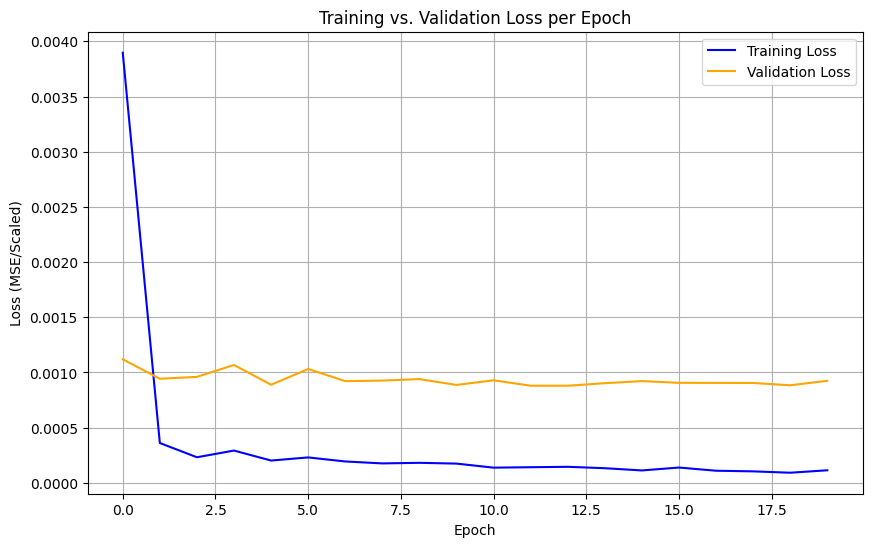

Final Training Loss: 0.000114
Final Validation Loss: 0.000925
Final Test Loss: 0.0002


In [412]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plotting both on the same axes
plt.plot(train_loss, label='Training Loss', color='blue')
plt.plot(val_loss, label='Validation Loss', color='orange')

# Training and Validation Plot
plt.title('Training vs. Validation Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE/Scaled)')
plt.legend()
plt.grid(True)
plt.show()


print(f"Final Training Loss: {train_loss[-1]:.6f}")
print(f"Final Validation Loss: {val_loss[-1]:.6f}")
print(f"Final Test Loss: {test_loss[-1]:.4f}")

In [413]:
print(f"Rapporto val/train loss finale: {val_loss[-1]/train_loss[-1]:.1f}x")

Rapporto val/train loss finale: 8.1x


In [414]:
model.eval()
print("Loss media per coppia (B,L) nel VAL set:")
print("-" * 45)

for (B, L), gruppo in df_val.groupby(['B_magn_T','TPU_L_mm']):
    # Costruisci tensori per questa coppia
    X_scalar = gruppo[['B_magn_T','TPU_L_mm','Strain_target']].values
    X_curve  = np.stack(gruppo['H_init_curve'].values)
    X_bl     = np.concatenate([X_scalar, X_curve], axis=1)
    y_bl     = np.stack(gruppo['dH_curve'].values)

    X_bl_sc  = scaler_X.transform(X_bl)
    y_bl_sc  = scaler_y.transform(y_bl)

    X_t = torch.tensor(X_bl_sc, dtype=torch.float32)
    y_t = torch.tensor(y_bl_sc, dtype=torch.float32)

    with torch.no_grad():
        pred = model(X_t)
        loss = loss_criterion(pred, y_t).item()

    print(f"  B={B:.4f} T  L={L:.1f} mm  →  loss = {loss:.6f}")

Loss media per coppia (B,L) nel VAL set:
---------------------------------------------
  B=0.0632 T  L=24.0 mm  →  loss = 0.000017
  B=0.0632 T  L=27.0 mm  →  loss = 0.000017
  B=0.0632 T  L=30.0 mm  →  loss = 0.000020
  B=0.0632 T  L=32.0 mm  →  loss = 0.000021
  B=0.1263 T  L=20.0 mm  →  loss = 0.000033
  B=0.1263 T  L=31.0 mm  →  loss = 0.000017
  B=0.1263 T  L=33.0 mm  →  loss = 0.000019
  B=0.1263 T  L=40.0 mm  →  loss = 0.000018
  B=0.1895 T  L=22.0 mm  →  loss = 0.000035
  B=0.1895 T  L=36.0 mm  →  loss = 0.000026
  B=0.1895 T  L=39.0 mm  →  loss = 0.000020
  B=0.1895 T  L=40.0 mm  →  loss = 0.000019
  B=0.2526 T  L=36.0 mm  →  loss = 0.000014
  B=0.2526 T  L=40.0 mm  →  loss = 0.000020
  B=0.3158 T  L=23.0 mm  →  loss = 0.000024
  B=0.3158 T  L=35.0 mm  →  loss = 0.000015
  B=0.3158 T  L=38.0 mm  →  loss = 0.000113
  B=0.3158 T  L=39.0 mm  →  loss = 0.000109
  B=0.3789 T  L=20.0 mm  →  loss = 0.000036
  B=0.3789 T  L=21.0 mm  →  loss = 0.000042
  B=0.3789 T  L=25.0 mm  →  loss 

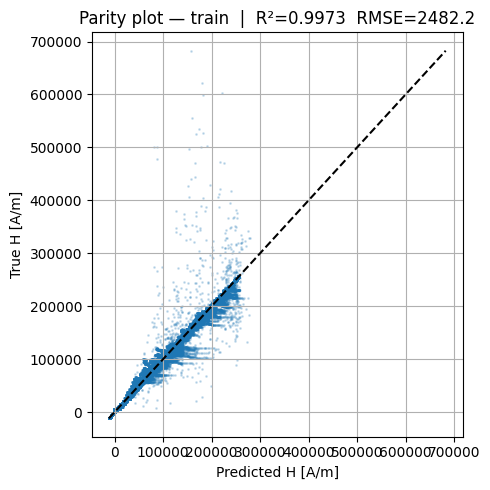

train: RMSE = 2482.20 A/m  |  R² = 0.9973


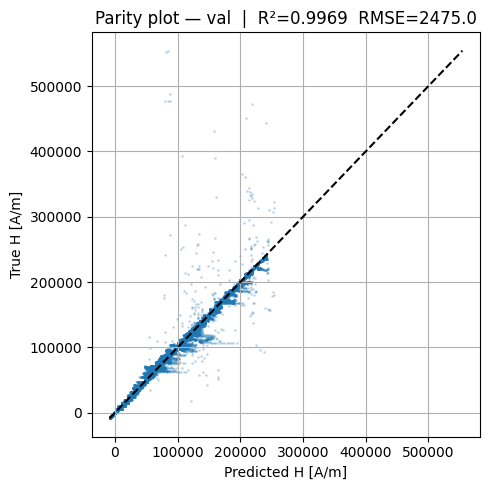

val: RMSE = 2474.98 A/m  |  R² = 0.9969


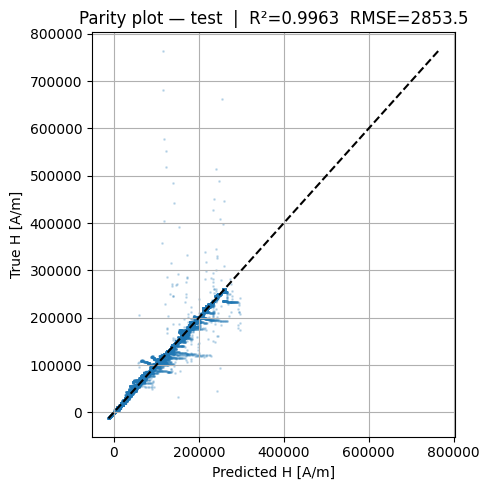

test: RMSE = 2853.53 A/m  |  R² = 0.9963


In [415]:
from sklearn.metrics import r2_score

def assess_results(model, X_tensor, y_tensor, scaler_y, H_init_array, data_type):
    model.eval()
    with torch.no_grad():
        dH_pred_sc = model(X_tensor).numpy()

    # Inverti scaling
    dH_pred = scaler_y.inverse_transform(dH_pred_sc)        # (N, 64)
    dH_true = scaler_y.inverse_transform(y_tensor.numpy())  # (N, 64)

    # Ricostruisci H assoluto
    H_pred = H_init_array + dH_pred   # (N, 64)
    H_true = H_init_array + dH_true   # (N, 64)

    # Appiattisci per metriche e parity plot
    H_pred_flat = H_pred.flatten()
    H_true_flat = H_true.flatten()

    r2   = r2_score(H_true_flat, H_pred_flat)
    rmse = np.sqrt(np.mean((H_pred_flat - H_true_flat)**2))

    lim = [H_true_flat.min(), H_true_flat.max()]
    plt.figure(figsize=(5, 5))
    plt.scatter(H_pred_flat, H_true_flat, s=1, alpha=0.2)
    plt.plot(lim, lim, 'k--')
    plt.xlabel('Predicted H [A/m]')
    plt.ylabel('True H [A/m]')
    plt.title(f'Parity plot — {data_type}  |  R²={r2:.4f}  RMSE={rmse:.1f}')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print(f'{data_type}: RMSE = {rmse:.2f} A/m  |  R² = {r2:.4f}')
    return rmse, r2, H_pred, H_true   # restituiamo anche le matrici per i boxplot

# Estrai H_init dai tre split (valori reali, non scalati)
H_init_train = np.stack(df_train['H_init_curve'].values)
H_init_val   = np.stack(df_val['H_init_curve'].values)
H_init_test  = np.stack(df_test['H_init_curve'].values)

rmse_tr, r2_tr, H_pred_train, H_true_train = assess_results(
    model, X_train_tensor, y_train_tensor, scaler_y, H_init_train, 'train')
rmse_vl, r2_vl, H_pred_val,   H_true_val   = assess_results(
    model, X_val_tensor,   y_val_tensor,   scaler_y, H_init_val,   'val')
rmse_ts, r2_ts, H_pred_test,  H_true_test  = assess_results(
    model, X_test_tensor,  y_test_tensor,  scaler_y, H_init_test,  'test')

(80, 2)
Coppia scelta: B=0.0631578947368421 T, L=29 mm


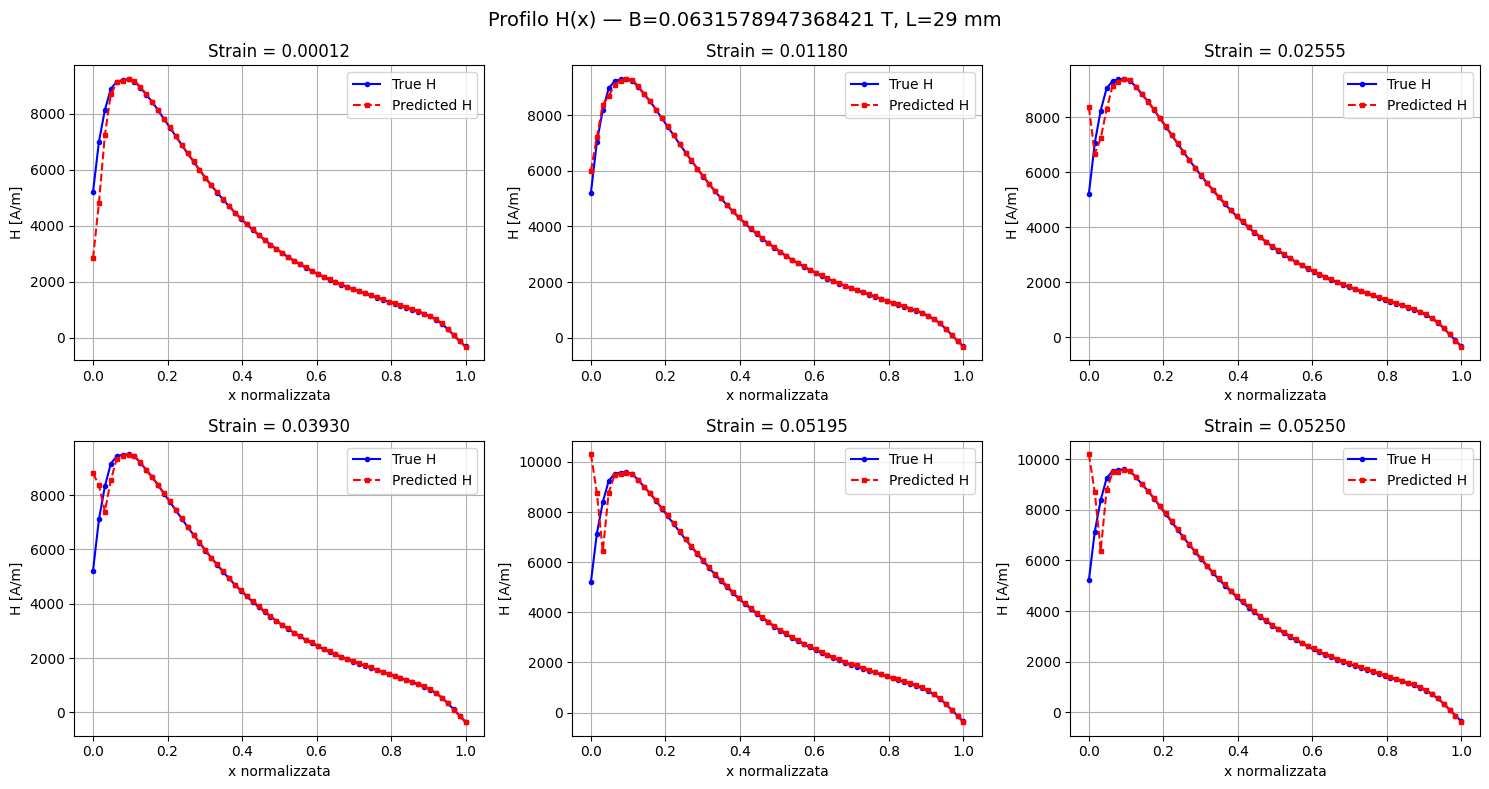

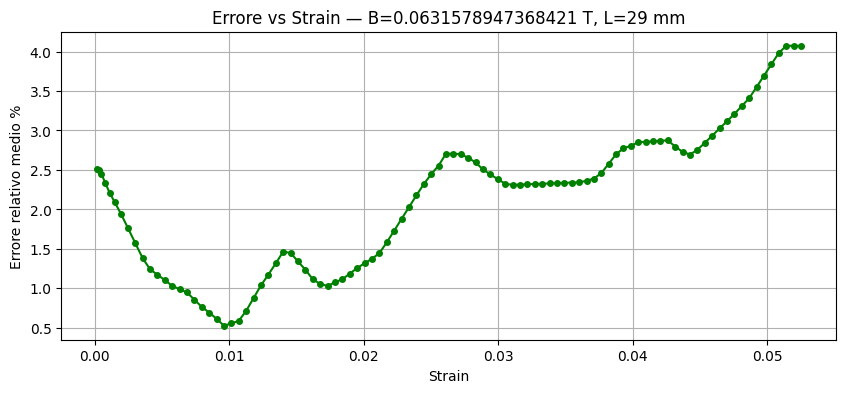

Errore medio globale: 2.12%
Errore max:           4.07%


In [416]:
# ================================================================
# VISUALIZZAZIONE CURVE PER UNA COPPIA (B, L)
# ================================================================

# Scegli una coppia dal test set (mai vista in training)
coppie_test = (df_test[['B_magn_T','TPU_L_mm']]
               .drop_duplicates()
               .sort_values(['B_magn_T','TPU_L_mm'])
               .reset_index(drop=True))
print(coppie_test.shape)

# Scegli la coppia che vuoi ispezionare
B_test = coppie_test['B_magn_T'].iloc[2]
L_test = coppie_test['TPU_L_mm'].iloc[2]
print(f"Coppia scelta: B={B_test} T, L={L_test} mm")

# Filtra df_curves sul test set per questa coppia
subset = df_test[
    np.isclose(df_test['B_magn_T'], B_test) &
    (df_test['TPU_L_mm'] == L_test)
].sort_values('Strain_target').reset_index(drop=True)

strain_steps = subset['Strain_target'].values          # (n_strain,)
H_init_mat   = np.stack(subset['H_init_curve'].values) # (n_strain, 64)
dH_true_mat  = np.stack(subset['dH_curve'].values)     # (n_strain, 64)

# Costruisci input e predici
X_subset = np.concatenate([
    subset[['B_magn_T','TPU_L_mm','Strain_target']].values,
    H_init_mat
], axis=1)

X_subset_sc = scaler_X.transform(X_subset)
X_subset_t  = torch.tensor(X_subset_sc, dtype=torch.float32)

model.eval()
with torch.no_grad():
    dH_pred_sc = model(X_subset_t).numpy()

dH_pred = scaler_y.inverse_transform(dH_pred_sc)  # (n_strain, 64)

# Ricostruisci H assoluto
H_pred_mat = H_init_mat + dH_pred    # (n_strain, 64)
H_true_mat = H_init_mat + dH_true_mat

# Griglia x normalizzata usata nell'interpolazione
x_fixed = np.linspace(0, 1, 64)

# ---- Plot 6 istanti di strain ----
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
t_da_plottare = [0,
                 len(strain_steps)//4,
                 len(strain_steps)//2,
                 3*len(strain_steps)//4,
                 -2, -1]

for ax, t_idx in zip(axes.flatten(), t_da_plottare):
    ax.plot(x_fixed, H_true_mat[t_idx], 'b-o',  label='True H',      markersize=3)
    ax.plot(x_fixed, H_pred_mat[t_idx], 'r--s', label='Predicted H', markersize=3)
    ax.set_title(f'Strain = {strain_steps[t_idx]:.5f}')
    ax.set_xlabel('x normalizzata')
    ax.set_ylabel('H [A/m]')
    ax.legend()
    ax.grid(True)

plt.suptitle(f'Profilo H(x) — B={B_test} T, L={L_test} mm', fontsize=14)
plt.tight_layout()
plt.show()

# ---- Errore relativo per strain step ----
err_per_strain = (np.mean(np.abs(H_pred_mat - H_true_mat), axis=1) /
                  (np.mean(np.abs(H_true_mat), axis=1) + 1e-4)) * 100

plt.figure(figsize=(10, 4))
plt.plot(strain_steps, err_per_strain, 'g-o', markersize=4)
plt.xlabel('Strain')
plt.ylabel('Errore relativo medio %')
plt.title(f'Errore vs Strain — B={B_test} T, L={L_test} mm')
plt.grid(True)
plt.show()

print(f"Errore medio globale: {np.mean(err_per_strain):.2f}%")
print(f"Errore max:           {np.max(err_per_strain):.2f}%")

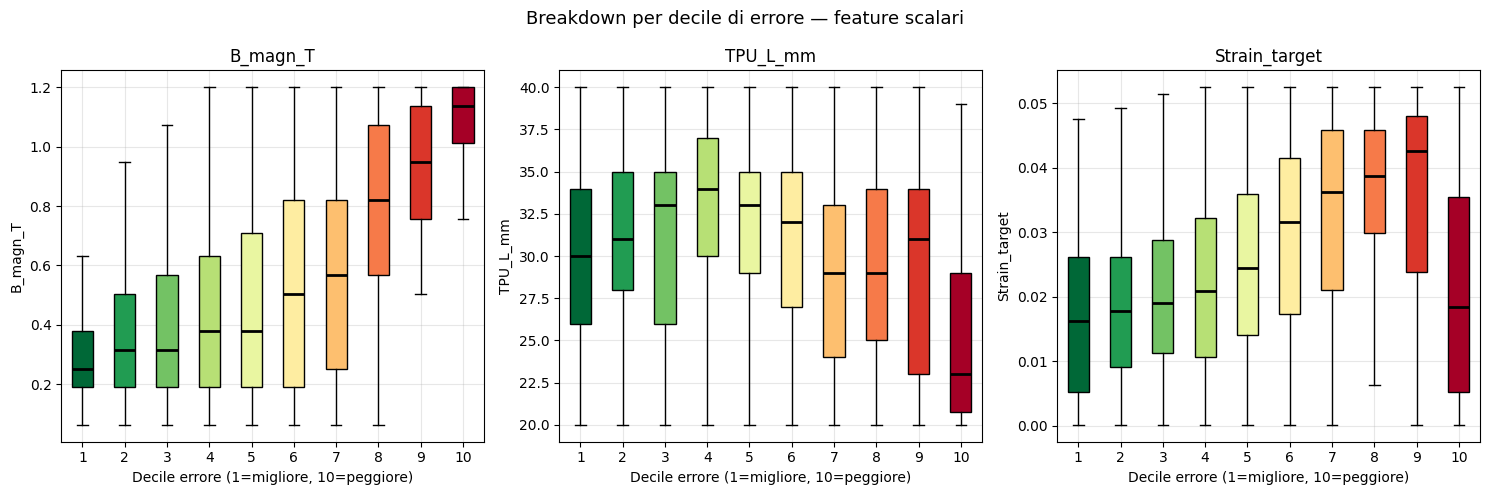

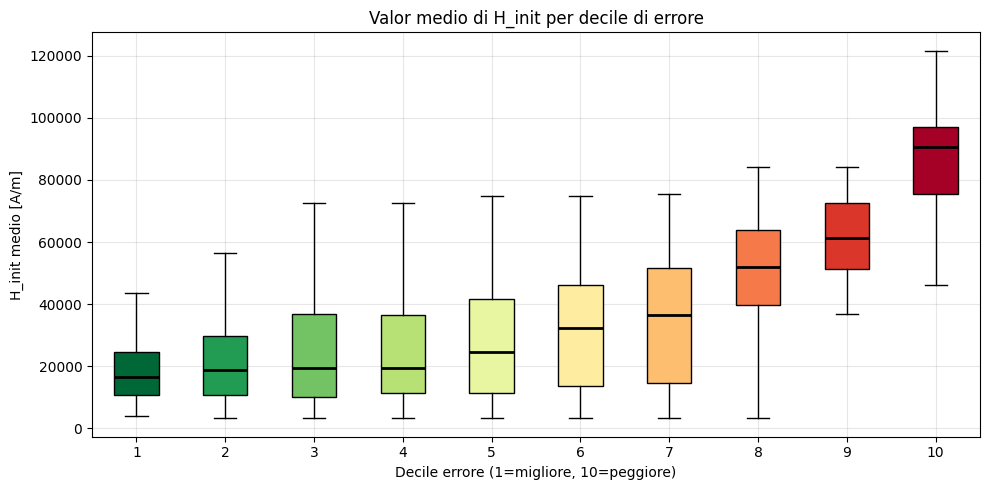

In [417]:
# Nomi delle 67 colonne di input
feature_names = (['B_magn_T', 'TPU_L_mm', 'Strain_target'] + 
                 [f'H_init_x{i}' for i in range(64)])

# Errore assoluto su H ricostruito, appiattito per campione (media sui 64 punti)
err_abs_per_curva = np.mean(np.abs(H_pred_test - H_true_test), axis=1)  # (N,)

# Decili sull'errore medio per curva — ogni curva va in un decile
bins_err = pd.qcut(err_abs_per_curva, q=10, duplicates='drop', labels=False)

# Plottiamo solo le 3 feature scalari (B, L, Strain) — i 64 H_init sono troppi
# Se vuoi anche H_init, cambia features_to_plot
features_to_plot = [0, 1, 2]   # indici di B, L, Strain in X_test
labels_to_plot   = ['B_magn_T', 'TPU_L_mm', 'Strain_target']

cmap_bp = plt.cm.RdYlGn_r
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Breakdown per decile di errore — feature scalari', fontsize=13)

for ax, feat_idx, feat_name in zip(axes, features_to_plot, labels_to_plot):
    # Valori NON scalati: prendiamo da X_test (numpy) colonna feat_idx
    feat_vals = X_test[:, feat_idx]

    data_by_dec = [feat_vals[bins_err == i] for i in range(10)]

    bp = ax.boxplot(data_by_dec, patch_artist=True, showfliers=False,
                    medianprops=dict(color='black', lw=2))
    for patch, i in zip(bp['boxes'], range(10)):
        patch.set_facecolor(cmap_bp(i / 9))

    ax.set_xlabel('Decile errore (1=migliore, 10=peggiore)')
    ax.set_ylabel(feat_name)
    ax.set_title(feat_name)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('boxplot_decile_errore.png', dpi=150, bbox_inches='tight')
plt.show()

# Aggiunta: boxplot del profilo medio di H_init per decile
# Mostra se la rete sbaglia di più su certi profili di H iniziale
fig, ax = plt.subplots(figsize=(10, 5))
H_init_mean_per_curva = np.mean(H_init_test, axis=1)  # valore medio di H_init per curva
data_by_dec = [H_init_mean_per_curva[bins_err == i] for i in range(10)]

bp = ax.boxplot(data_by_dec, patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=2))
for patch, i in zip(bp['boxes'], range(10)):
    patch.set_facecolor(cmap_bp(i / 9))

ax.set_xlabel('Decile errore (1=migliore, 10=peggiore)')
ax.set_ylabel('H_init medio [A/m]')
ax.set_title('Valor medio di H_init per decile di errore')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### NN initialization

### Assessment and results


In [418]:
print(corr)

0.9877048196002736


### TEST: ASK AND SHALL BE ANSWERED

In [419]:
# get the new data from COMSOL


# Sostituisci con il percorso reale del tuo file
file_path = "new_decimal_dataset.txt"

# Leggiamo il file ignorando le righe che iniziano con '%'
# Usiamo uno spazio generico o tabulazione come separatore
dz = pd.read_csv(
    file_path, 
    comment='%', 
    sep=r'\s+', 
    names=['Arc_length', 'Magnetic_field']
)

print(f"Caricate con successo {len(dz)} righe!")
print(dz.head())

Caricate con successo 210585 righe!
   Arc_length  Magnetic_field
0    0.000000             0.0
1    0.000119             0.0
2    0.000238             0.0
3    0.000357             0.0
4    0.000477             0.0


In [420]:
# remove the zero values
dz_senza_zero = dz[dz['Magnetic_field'] != 0]
print(len(dz_senza_zero))

168468


In [421]:
import pandas as pd
import numpy as np

file_path = "new_decimal_dataset.txt"

# 1. Carichiamo tutto il file sapendo che ha SOLO due colonne numeriche
# Usiamo comment='%' se ci fossero righe di commento solo all'inizio del file
dz = pd.read_csv(
    file_path, 
    comment='%', 
    sep=r'\s+', 
    names=['X', 'H'],
    header=None
)

# Convertiamo i dati in numeri (rimuovendo eventuali righe di testo spurie)
dz['X'] = pd.to_numeric(dz['X'], errors='coerce')
dz['H'] = pd.to_numeric(dz['H'], errors='coerce')
dz = dz.dropna().reset_index(drop=True)

# 2. Troviamo i punti di inizio di ogni nuova curva
# Una nuova curva inizia quando la X della riga corrente è MINORE della X della riga precedente
condizione_inizio = dz['X'].diff() < 0
indici_inizio = dz[condizione_inizio].index.tolist()

# Inseriamo l'indice della primissima riga (0) all'inizio della lista
indici_taglio = [0] + indici_inizio + [len(dz)]

# 3. Separiamo il colosso di due colonne in un dizionario di curve distinte
tutti_i_dati = {}
for i in range(len(indici_taglio) - 1):
    start = indici_taglio[i]
    end = indici_taglio[i+1]
    
    # Estraiamo il blocco di righe della curva corrente
    dz_curva = dz.iloc[start:end].reset_index(drop=True)
    
    # Salviamo la curva nel dizionario (es. Curva_0, Curva_1, ecc.)
    tutti_i_dati[f"Curva_{i}"] = dz_curva

print(f"File letto con successo!")
print(f"Numero totale di righe nel file: {len(dz)}")
print(f"Numero di curve distinte individuate: {len(tutti_i_dati)}")

# Esempio: prendiamo la prima curva
dz_prima = tutti_i_dati["Curva_0"]
print("\nPrime righe della prima curva (Curva_0):")
print(dz_prima.head())

File letto con successo!
Numero totale di righe nel file: 210585
Numero di curve distinte individuate: 1515

Prime righe della prima curva (Curva_0):
          X    H
0  0.000000  0.0
1  0.000119  0.0
2  0.000238  0.0
3  0.000357  0.0
4  0.000477  0.0


In [422]:
tutti_i_dati.items()

dict_items([('Curva_0',             X    H
0    0.000000  0.0
1    0.000119  0.0
2    0.000238  0.0
3    0.000357  0.0
4    0.000477  0.0
..        ...  ...
122  0.018823  0.0
123  0.018943  0.0
124  0.019062  0.0
125  0.019181  0.0
126  0.019300  0.0

[127 rows x 2 columns]), ('Curva_1',             X    H
0    0.000000  0.0
1    0.000119  0.0
2    0.000238  0.0
3    0.000357  0.0
4    0.000477  0.0
..        ...  ...
122  0.018823  0.0
123  0.018943  0.0
124  0.019062  0.0
125  0.019181  0.0
126  0.019300  0.0

[127 rows x 2 columns]), ('Curva_2',             X    H
0    0.000000  0.0
1    0.000119  0.0
2    0.000238  0.0
3    0.000357  0.0
4    0.000477  0.0
..        ...  ...
122  0.018823  0.0
123  0.018943  0.0
124  0.019062  0.0
125  0.019181  0.0
126  0.019300  0.0

[127 rows x 2 columns]), ('Curva_3',             X    H
0    0.000000  0.0
1    0.000119  0.0
2    0.000238  0.0
3    0.000357  0.0
4    0.000477  0.0
..        ...  ...
122  0.018823  0.0
123  0.018943  0.0
124  0.

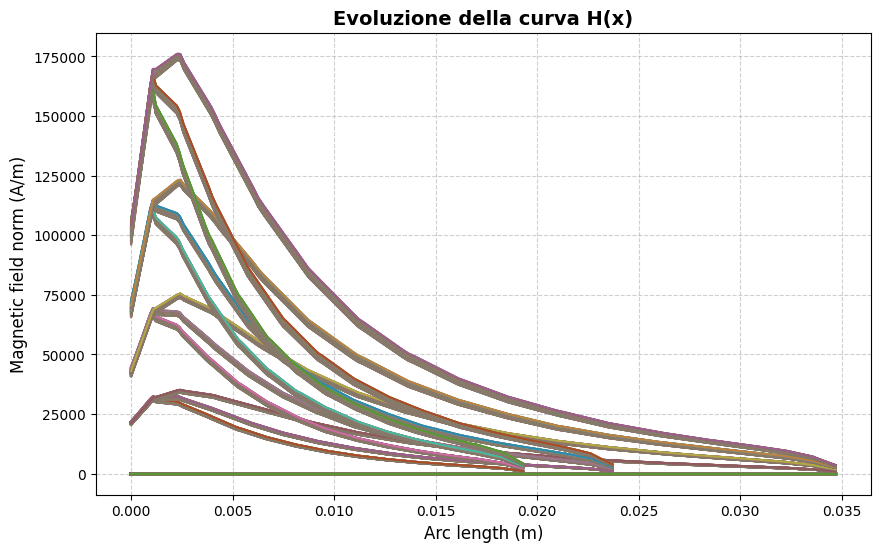

In [423]:
# plot on the same graph

# Creiamo la figura del grafico
plt.figure(figsize=(10, 6))

# Cicliamo su tutte le curve memorizzate nel dizionario
for nome_curva, dz_curva in tutti_i_dati.items():
    # Opzionale: se vuoi rimuovere i valori a zero prima del plot, scommenta la riga sotto
    # dz_curva = dz_curva[dz_curva['H'] != 0]
    
    # Plottiamo l'asse X (Arc length) contro l'asse H (Magnetic field)
    # Nota: non mettiamo la label per ogni curva se sono troppe, altrimenti la legenda esplode
    plt.plot(dz_curva['X'], dz_curva['H'], alpha=0.7, linewidth=1.5)

# Personalizziamo il grafico per renderlo leggibile e professionale
plt.title("Evoluzione della curva H(x)", fontsize=14, fontweight='bold')
plt.xlabel("Arc length (m)", fontsize=12)
plt.ylabel("Magnetic field norm (A/m)", fontsize=12)

# Attiviamo la griglia di sfondo (comoda come quella di COMSOL)
plt.grid(True, linestyle='--', alpha=0.6)

# Mostriamo il grafico a schermo
plt.show()


--- Suddivisione in Macro-Blocchi completata ---
Creati 5 macro-blocchi, ognuno contenente 303 curve.


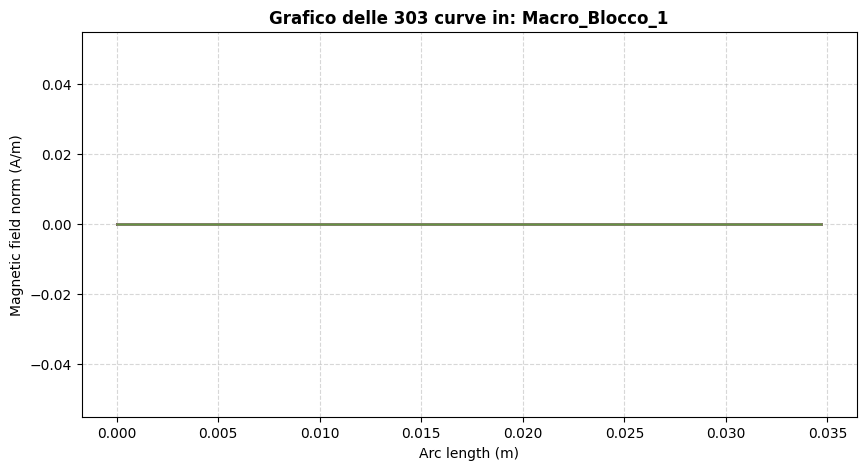

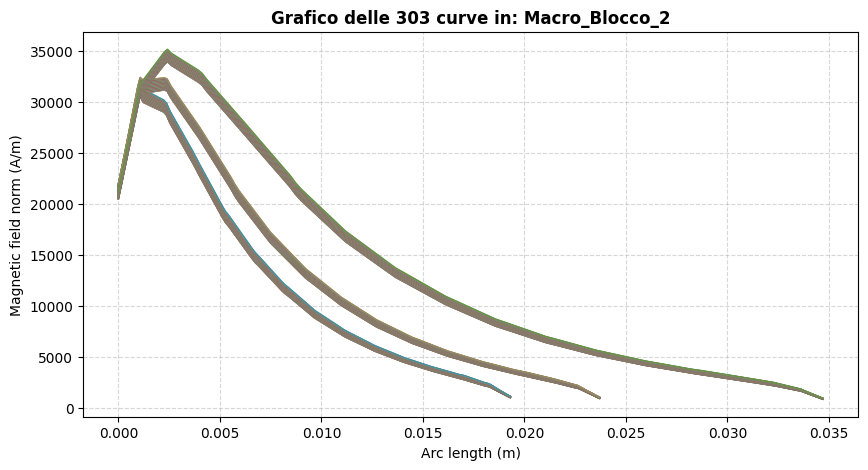

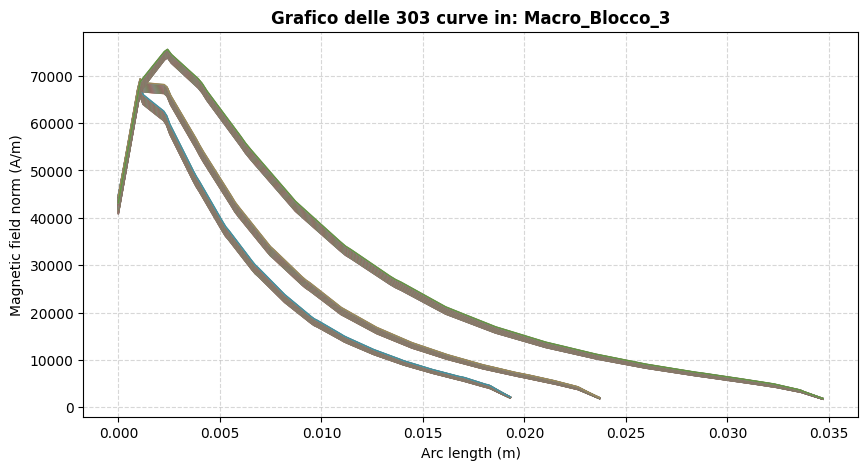

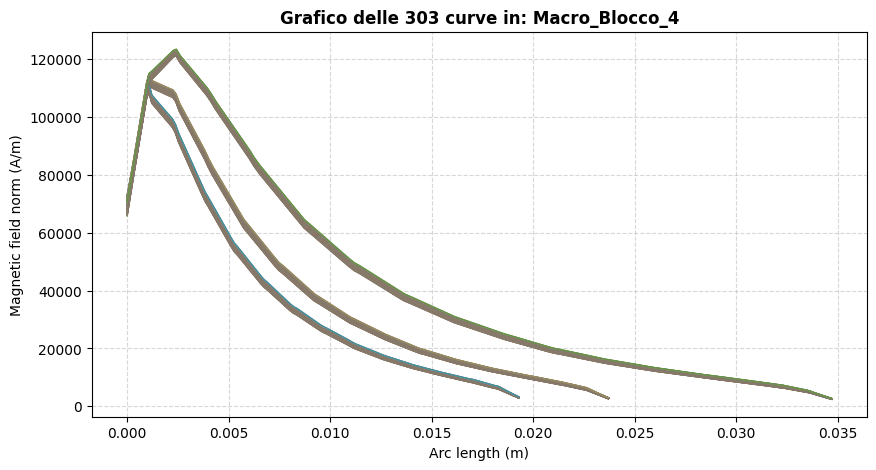

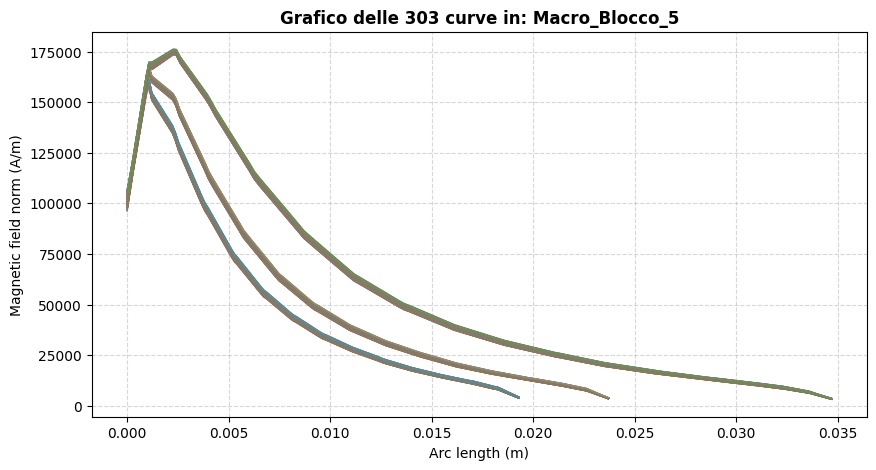

In [424]:
# --- 4. Raggruppamento in macro-blocchi di 303 curve ---

curve_per_blocco = 303
nomi_curve = list(tutti_i_dati.keys()) # Lista con "Curva_0", "Curva_1", ..., "Curva_1514"
totale_curve = len(nomi_curve)

# Calcoliamo quanti macro-blocchi completi ci sono (1515 / 303 = 5)
num_macro_blocchi = totale_curve // curve_per_blocco

macro_blocchi = {}

for b in range(num_macro_blocchi):
    start_curva = b * curve_per_blocco
    end_curva = start_curva + curve_per_blocco
    
    # Prendiamo i nomi delle 303 curve che appartengono a questo blocco
    curve_del_blocco = nomi_curve[start_curva:end_curva]
    
    # Salvia mo un sotto-dizionario con solo queste 303 curve
    macro_blocchi[f"Macro_Blocco_{b+1}"] = {
        nome: tutti_i_dati[nome] for nome in curve_del_blocco
    }

print(f"\n--- Suddivisione in Macro-Blocchi completata ---")
print(f"Creati {len(macro_blocchi)} macro-blocchi, ognuno contenente {curve_per_blocco} curve.")


# --- 5. Plot separato per ogni macro-blocco ---
# Questo creerà 5 finestre/grafici differenti, uno per blocco

for nome_macro, sotto_dizionario in macro_blocchi.items():
    plt.figure(figsize=(10, 5))
    
    # Plottiamo le 303 curve di QUESTO macro-blocco
    for nome_curva, dz_curva in sotto_dizionario.items():
        plt.plot(dz_curva['X'], dz_curva['H'], alpha=0.5, linewidth=1.0)
        
    plt.title(f"Grafico delle 303 curve in: {nome_macro}", fontsize=12, fontweight='bold')
    plt.xlabel("Arc length (m)")
    plt.ylabel("Magnetic field norm (A/m)")
    plt.grid(True, linestyle='--', alpha=0.5)
    
    # Se usi Jupyter Notebook si vedranno uno sotto l'altro, 
    # se usi uno script standard Python si apriranno in sequenza.
    plt.show()

In [425]:
# load the strain

file_path = "strain_dataset.txt"

# 1. Carichiamo tutto il file sapendo che ha SOLO due colonne numeriche
# Usiamo comment='%' se ci fossero righe di commento solo all'inizio del file
dw = pd.read_csv(
    file_path, 
    comment='%', 
    sep=r'\s+', 
    names=['Strain', 'Stress'],
    header=None
)

In [426]:
strain = dw['Strain'].values
print(dw.shape)
print(strain.shape)
dw.head()


(1515, 2)
(1515,)


,Strain,Stress
0,1.210000e-12,1.701980e-20
1,3.025000e-05,3.210295e-05
2,1.210000e-04,5.815817e-04
3,2.722500e-04,1.544304e-03
4,4.840000e-04,2.748774e-03


In [427]:
# create the new dataset

len(tutti_i_dati)
# Supponiamo che il tuo array/lista si chiami 'strain' ed è lungo 1515
# (Assicurati che sia definito prima di questo blocco)

# Usiamo enumerate per avere sia il nome della curva (chiave) sia l'indice numerico i
for i, nome_curva in enumerate(tutti_i_dati.keys()):
    
    # Estraiamo il valore di strain corrispondente a questa simulazione
    strain_corrente = strain[i]
    
    # Creiamo la nuova colonna nel DataFrame popolandola con il valore fisso
    tutti_i_dati[nome_curva]['Strain'] = strain_corrente

print("Assegnazione completata con successo!")

# Facciamo una verifica al volo stampando la prima e l'ultima curva
print("\nVerifica su 'Curva_0' (Strain atteso: strain[0]):")
print(tutti_i_dati['Curva_0'].head(3))

print(f"\nVerifica su 'Curva_1514' (Strain atteso: strain[1514]):")
print(tutti_i_dati['Curva_1514'].head(3))


Assegnazione completata con successo!

Verifica su 'Curva_0' (Strain atteso: strain[0]):
          X    H        Strain
0  0.000000  0.0  1.210000e-12
1  0.000119  0.0  1.210000e-12
2  0.000238  0.0  1.210000e-12

Verifica su 'Curva_1514' (Strain atteso: strain[1514]):
          X              H  Strain
0  0.000000  104250.295550  0.0525
1  0.000119  111660.059044  0.0525
2  0.000238  119068.204836  0.0525


In [428]:
print(tutti_i_dati['Curva_303'].tail(3))

            X            H        Strain
124  0.019062  1266.300756  1.210000e-12
125  0.019181  1145.807502  1.210000e-12
126  0.019300  1026.903937  1.210000e-12


In [429]:
# Add the B and the L to the dataset

In [430]:
# remove the first 302 curves where we have 0

tutti_i_dati_senza_zero = {nome: df for nome, df in tutti_i_dati.items() if not np.isclose(df['H'].iloc[0], 0)}

tutti_i_dati_senza_zero.keys()

dict_keys(['Curva_303', 'Curva_304', 'Curva_305', 'Curva_306', 'Curva_307', 'Curva_308', 'Curva_309', 'Curva_310', 'Curva_311', 'Curva_312', 'Curva_313', 'Curva_314', 'Curva_315', 'Curva_316', 'Curva_317', 'Curva_318', 'Curva_319', 'Curva_320', 'Curva_321', 'Curva_322', 'Curva_323', 'Curva_324', 'Curva_325', 'Curva_326', 'Curva_327', 'Curva_328', 'Curva_329', 'Curva_330', 'Curva_331', 'Curva_332', 'Curva_333', 'Curva_334', 'Curva_335', 'Curva_336', 'Curva_337', 'Curva_338', 'Curva_339', 'Curva_340', 'Curva_341', 'Curva_342', 'Curva_343', 'Curva_344', 'Curva_345', 'Curva_346', 'Curva_347', 'Curva_348', 'Curva_349', 'Curva_350', 'Curva_351', 'Curva_352', 'Curva_353', 'Curva_354', 'Curva_355', 'Curva_356', 'Curva_357', 'Curva_358', 'Curva_359', 'Curva_360', 'Curva_361', 'Curva_362', 'Curva_363', 'Curva_364', 'Curva_365', 'Curva_366', 'Curva_367', 'Curva_368', 'Curva_369', 'Curva_370', 'Curva_371', 'Curva_372', 'Curva_373', 'Curva_374', 'Curva_375', 'Curva_376', 'Curva_377', 'Curva_378', '

In [431]:
import numpy as np
import pandas as pd

# 1. Definiamo i tuoi parametri (assicurati che B includa l'1.2 se era presente nel modello)
B_used = np.arange(0, 1.2, 0.25)  # [0.25, 0.5, 0.75, 1.0] (5 elementi)
L_used = np.array([21.3, 25.7, 36.7])       # (3 elementi)
tempi_totali = 101

# Controlliamo la consistenza numerica
curve_per_B = len(L_used) * tempi_totali  # 303

# 2. Ciclo sulle 1515 curve per iniettare tutti i metadati parametrici e la normalizzazione
for i, nome_curva in enumerate(tutti_i_dati.keys()):
    
    # A) Associazione STRAIN (dalla tua lista/array di 1515 elementi)
    strain_corrente = strain[i]
    tutti_i_dati[nome_curva]['Strain'] = strain_corrente
    
    # B) Calcolo dell'indice di B e L corrispondente all'indice globale 'i'
    # Capiamo a quale blocco di B appartiene la curva (0, 1, 2, 3 o 4)
    indice_B = i // curve_per_B 
    B_corrente = B_used[indice_B]
    
    # Capiamo a quale dei 3 valori di L appartiene all'interno del blocco corrente
    # Togliamo l'effetto di B e dividiamo per i 101 passi temporali
    indice_L = (i % curve_per_B) // tempi_totali
    L_corrente = L_used[indice_L]
    
    # Iniettiamo B e L come colonne fisse nella curva attuale
    tutti_i_dati[nome_curva]['B_magn'] = B_corrente
    tutti_i_dati[nome_curva]['L_param'] = L_corrente
    
    # C) Calcolo di X_norm (Coordinata X divisa per L corrente)
    # ATTENZIONE: Se L_used è in mm e la tua X è in metri (0.033 m), 
    # convertiamo L in metri (dividendo per 1000) per avere un'adimensionalizzazione corretta!
    L_in_metri = L_corrente / 1000.0
    tutti_i_dati[nome_curva]['X_norm'] = tutti_i_dati[nome_curva]['X'] / L_in_metri

print("Assegnazione parametri (Strain, B, L) e calcolo X_norm completati con successo!")

# --- VERIFICA STRUTTURA DATI ---
# Stampiamo una curva a metà del dataset (es. la 350, che dovrebbe avere il secondo valore di B)
print("\nVerifica struttura colonne su 'Curva_350':")
print(tutti_i_dati['Curva_350'].head(3))

Assegnazione parametri (Strain, B, L) e calcolo X_norm completati con successo!

Verifica struttura colonne su 'Curva_350':
          X             H   Strain  B_magn  L_param    X_norm
0  0.000000  21385.686432  0.02335    0.25     21.3  0.000000
1  0.000119  22469.449647  0.02335    0.25     21.3  0.005593
2  0.000238  23573.300596  0.02335    0.25     21.3  0.011187


In [432]:
# remove the first 302 curves where we have 0

tutti_i_dati_senza_zero = {nome: df for nome, df in tutti_i_dati.items() if not np.isclose(df['H'].iloc[0], 0)}

tutti_i_dati_senza_zero.keys()

dict_keys(['Curva_303', 'Curva_304', 'Curva_305', 'Curva_306', 'Curva_307', 'Curva_308', 'Curva_309', 'Curva_310', 'Curva_311', 'Curva_312', 'Curva_313', 'Curva_314', 'Curva_315', 'Curva_316', 'Curva_317', 'Curva_318', 'Curva_319', 'Curva_320', 'Curva_321', 'Curva_322', 'Curva_323', 'Curva_324', 'Curva_325', 'Curva_326', 'Curva_327', 'Curva_328', 'Curva_329', 'Curva_330', 'Curva_331', 'Curva_332', 'Curva_333', 'Curva_334', 'Curva_335', 'Curva_336', 'Curva_337', 'Curva_338', 'Curva_339', 'Curva_340', 'Curva_341', 'Curva_342', 'Curva_343', 'Curva_344', 'Curva_345', 'Curva_346', 'Curva_347', 'Curva_348', 'Curva_349', 'Curva_350', 'Curva_351', 'Curva_352', 'Curva_353', 'Curva_354', 'Curva_355', 'Curva_356', 'Curva_357', 'Curva_358', 'Curva_359', 'Curva_360', 'Curva_361', 'Curva_362', 'Curva_363', 'Curva_364', 'Curva_365', 'Curva_366', 'Curva_367', 'Curva_368', 'Curva_369', 'Curva_370', 'Curva_371', 'Curva_372', 'Curva_373', 'Curva_374', 'Curva_375', 'Curva_376', 'Curva_377', 'Curva_378', '

In [433]:
tutti_i_dati_senza_zero['Curva_303']

,X,H,Strain,B_magn,L_param,X_norm
0,0.000000,20890.904604,1.210000e-12,0.25,21.3,0.000000
1,0.000119,21960.833241,1.210000e-12,0.25,21.3,0.005593
2,0.000238,23051.269623,1.210000e-12,0.25,21.3,0.011187
3,0.000357,24159.437059,1.210000e-12,0.25,21.3,0.016780
4,0.000477,25283.004172,1.210000e-12,0.25,21.3,0.022374
...,...,...,...,...,...,...
122,0.018823,1510.530391,1.210000e-12,0.25,21.3,0.883729
123,0.018943,1387.969746,1.210000e-12,0.25,21.3,0.889323
124,0.019062,1266.300756,1.210000e-12,0.25,21.3,0.894916
125,0.019181,1145.807502,1.210000e-12,0.25,21.3,0.900510


In [434]:
from scipy.interpolate import interp1d

# ================================================================
# INFERENCE + PLOT H_pred vs H_true PER COPPIA (B, L)
# ================================================================

ERR_MN = []
PAIR   = []

# Raggruppa le curve per coppia (B, L) — ogni coppia ha N_t snapshot
# Costruiamo un dizionario: (b_val, l_val) -> lista di curve ordinate per strain
from collections import defaultdict
coppie_dict = defaultdict(list)

for nome_curva, input_data in tutti_i_dati_senza_zero.items():
    b_val = input_data['B_magn'].iloc[0]
    l_val = input_data['L_param'].iloc[0]
    s_val = input_data['Strain'].iloc[0]
    coppie_dict[(b_val, l_val)].append((s_val, nome_curva, input_data))

# Ordina ogni coppia per strain crescente
for key in coppie_dict:
    coppie_dict[key].sort(key=lambda x: x[0])

print(f"Coppie (B,L) trovate: {len(coppie_dict)}")
for k, v in coppie_dict.items():
    print(f"  B={k[0]:.3f}, L={k[1]:.1f} mm → {len(v)} snapshot")

Coppie (B,L) trovate: 12
  B=0.250, L=21.3 mm → 101 snapshot
  B=0.250, L=25.7 mm → 101 snapshot
  B=0.250, L=36.7 mm → 101 snapshot
  B=0.500, L=21.3 mm → 101 snapshot
  B=0.500, L=25.7 mm → 101 snapshot
  B=0.500, L=36.7 mm → 101 snapshot
  B=0.750, L=21.3 mm → 101 snapshot
  B=0.750, L=25.7 mm → 101 snapshot
  B=0.750, L=36.7 mm → 101 snapshot
  B=1.000, L=21.3 mm → 101 snapshot
  B=1.000, L=25.7 mm → 101 snapshot
  B=1.000, L=36.7 mm → 101 snapshot


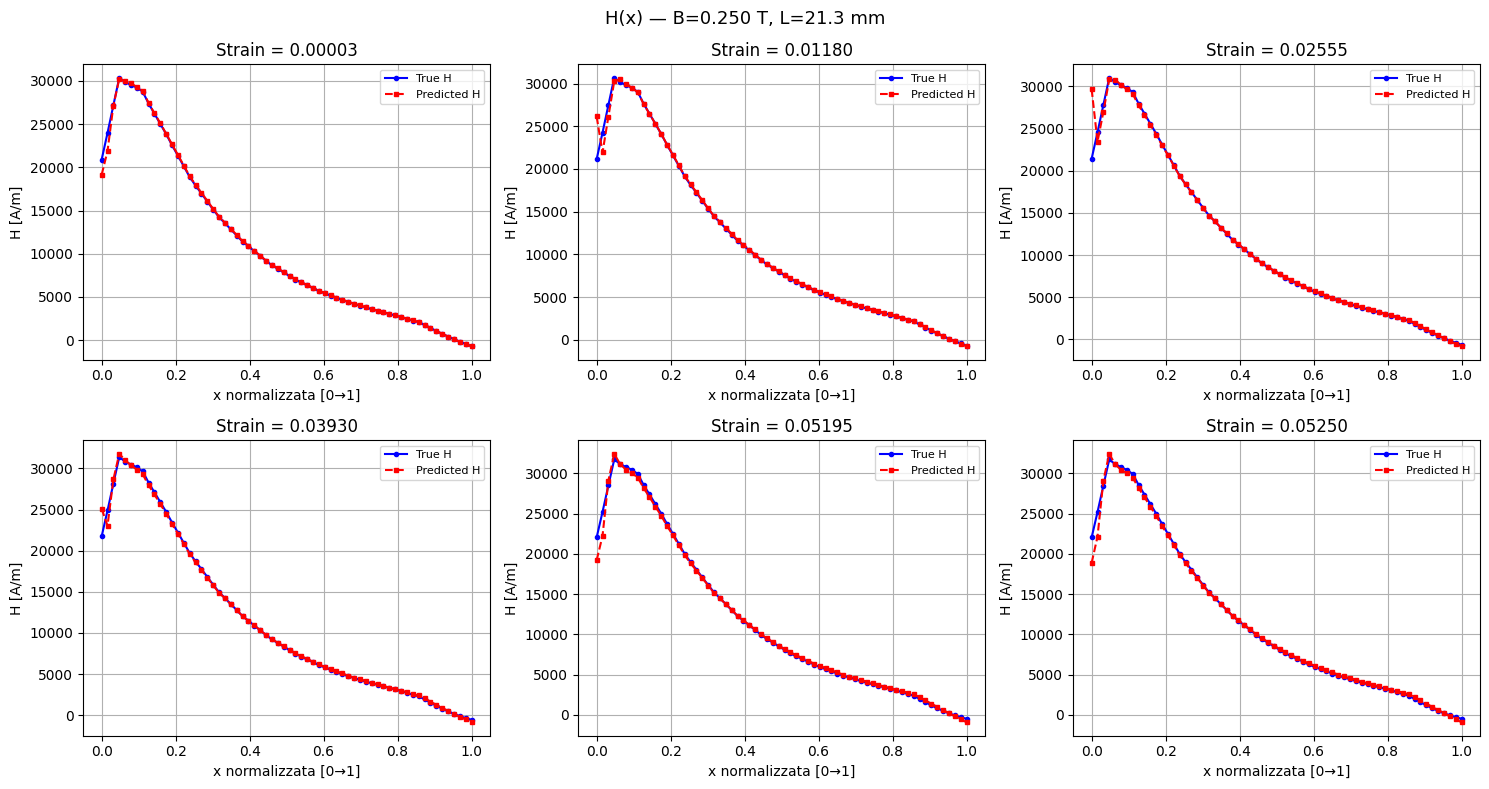

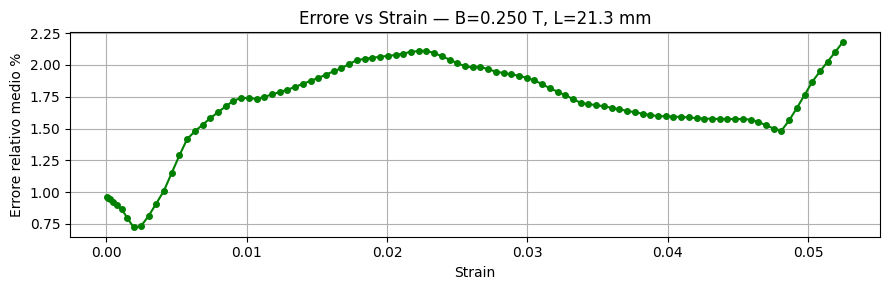

B=0.250 T, L=21.3 mm | Errore medio=1.67%  Max=2.18%


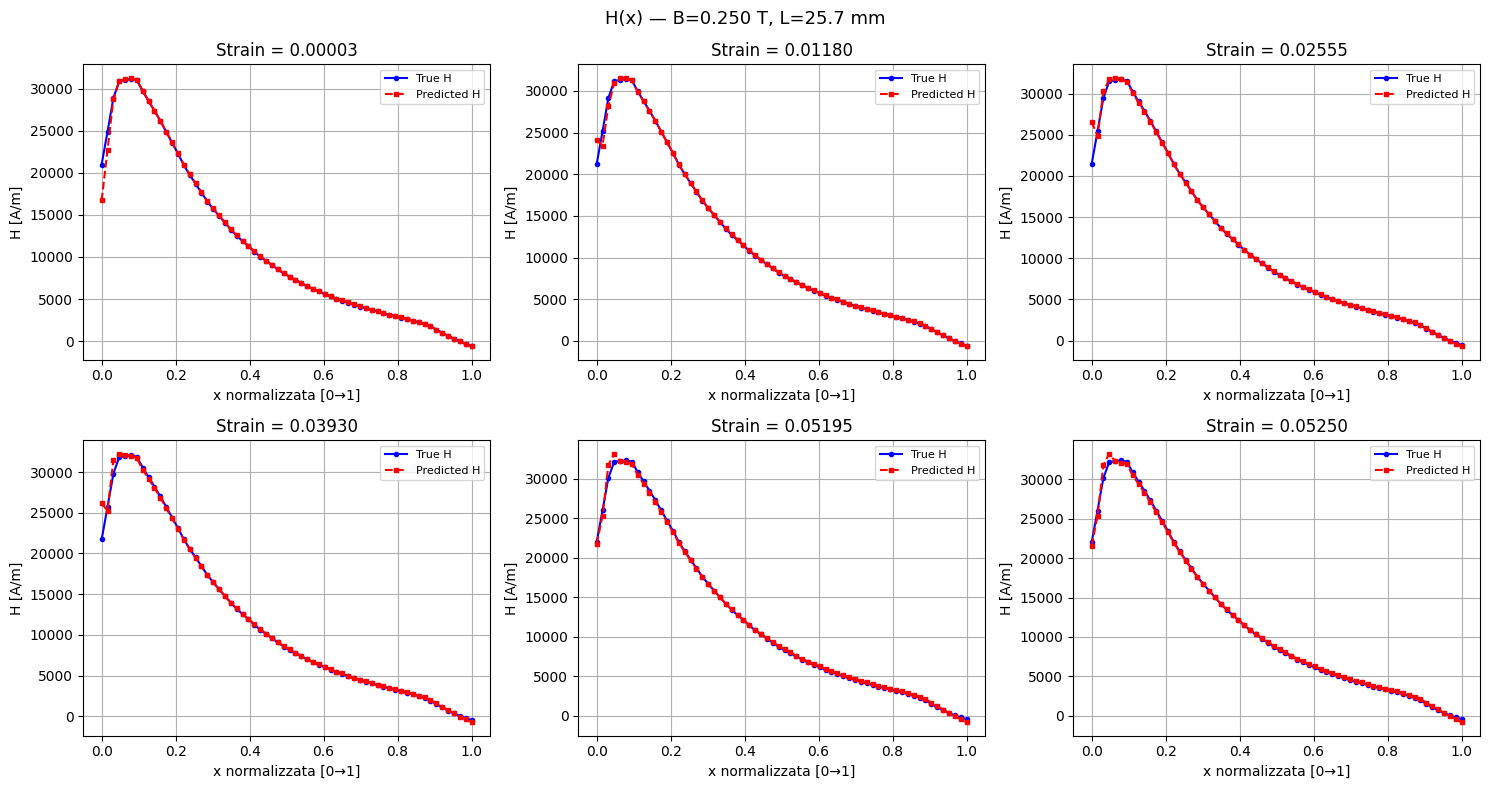

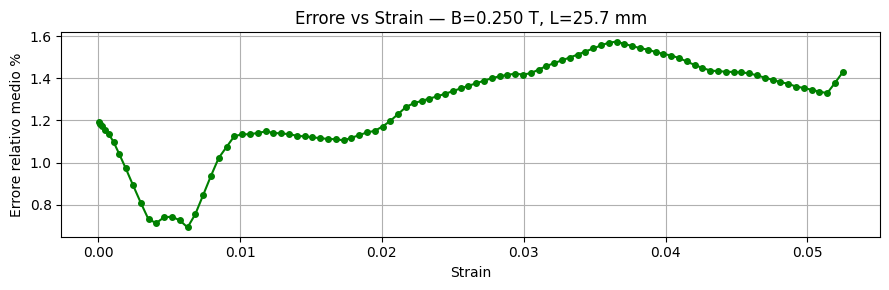

B=0.250 T, L=25.7 mm | Errore medio=1.26%  Max=1.57%


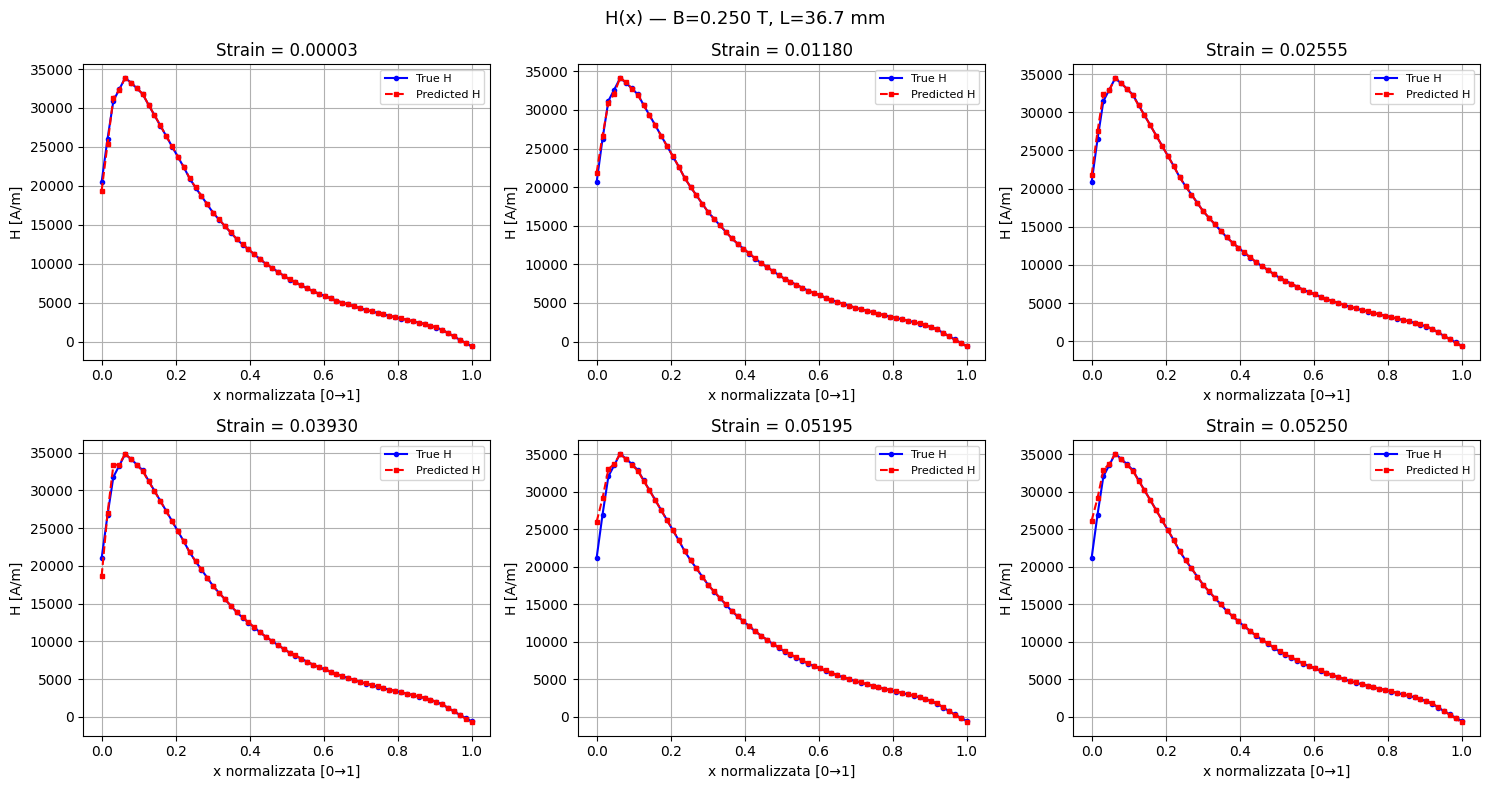

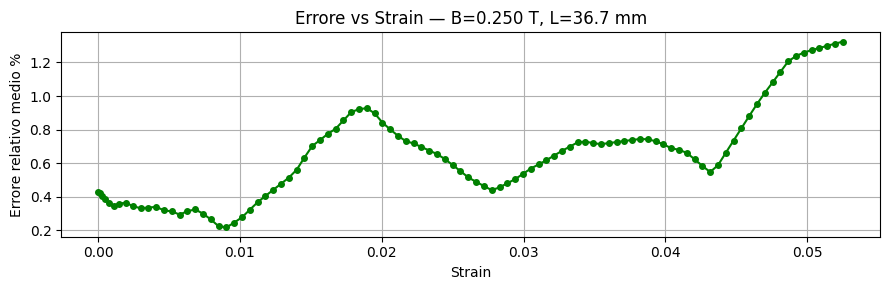

B=0.250 T, L=36.7 mm | Errore medio=0.65%  Max=1.32%


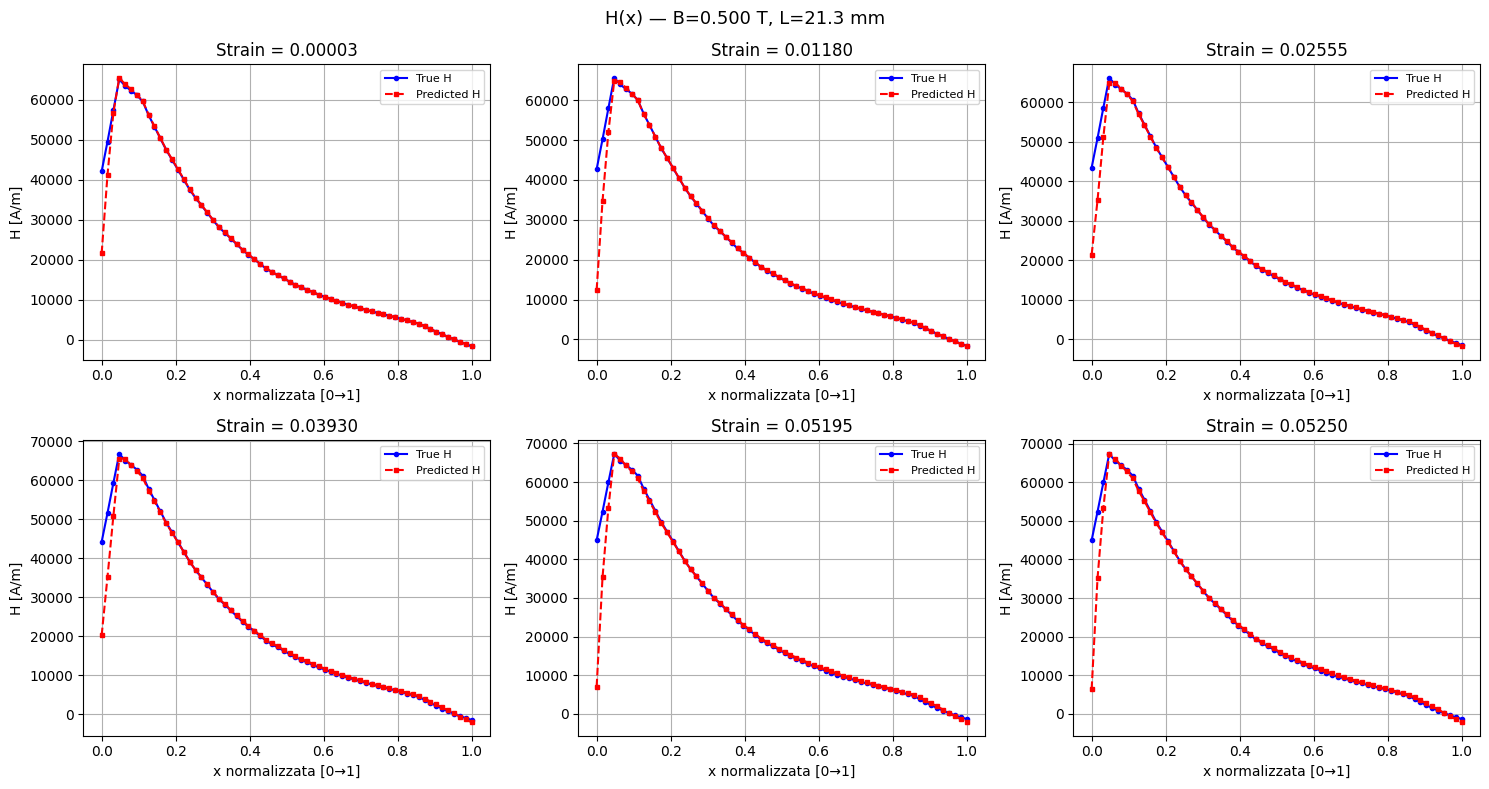

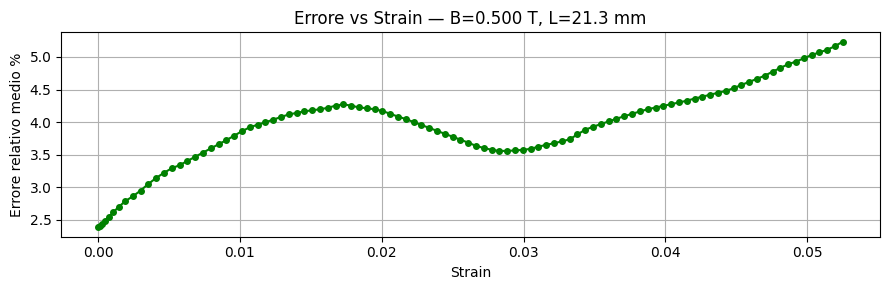

B=0.500 T, L=21.3 mm | Errore medio=3.93%  Max=5.24%


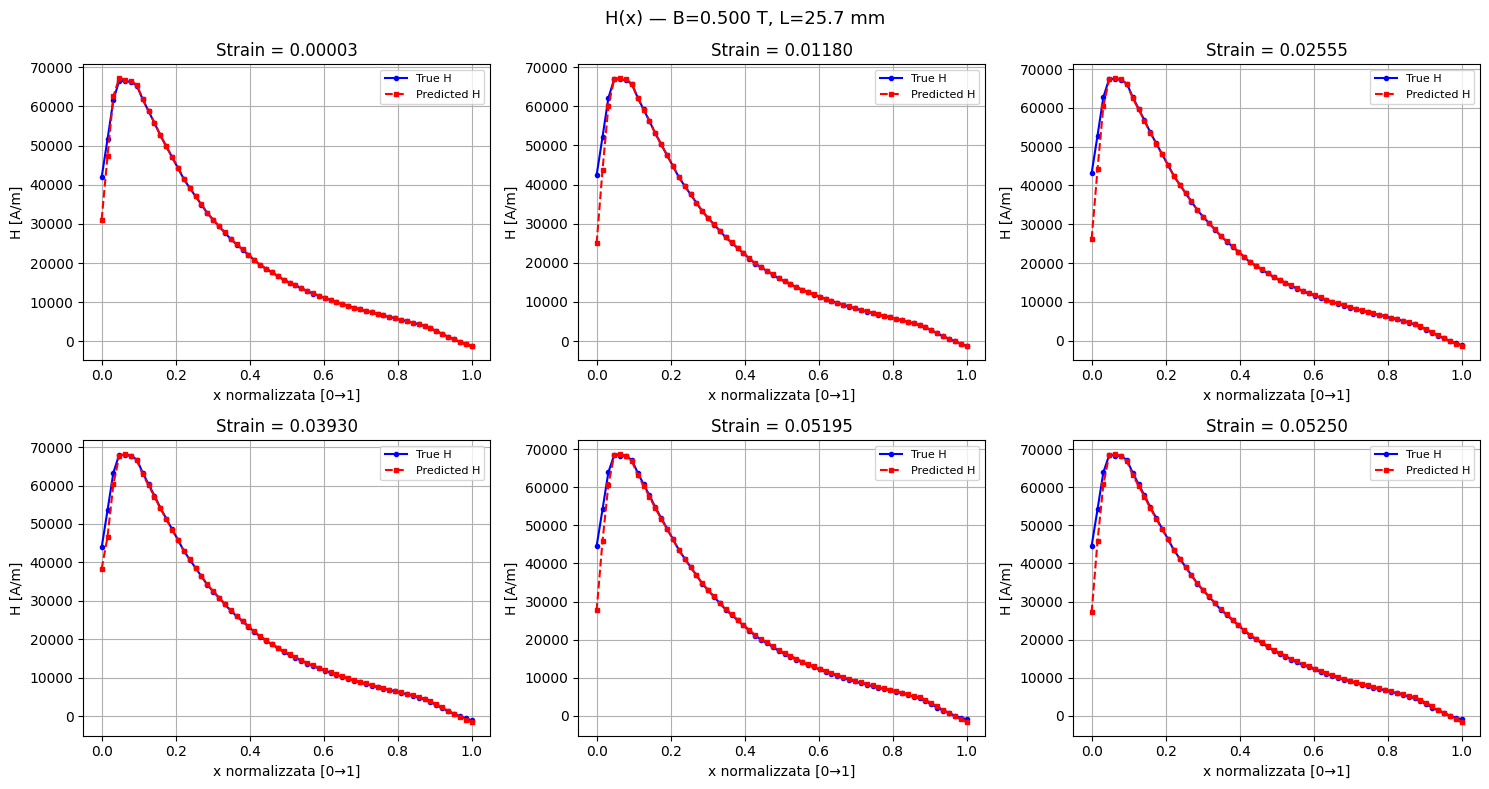

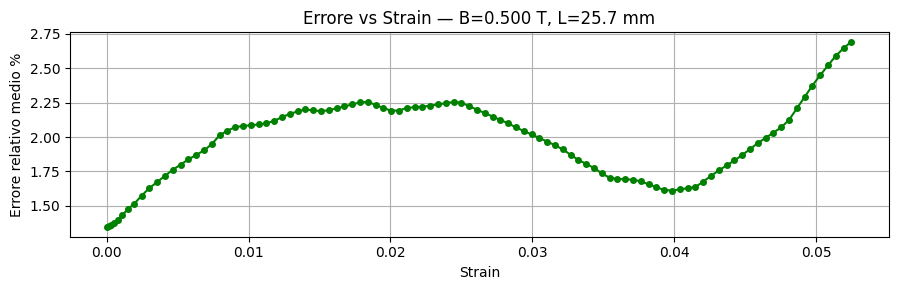

B=0.500 T, L=25.7 mm | Errore medio=1.97%  Max=2.69%


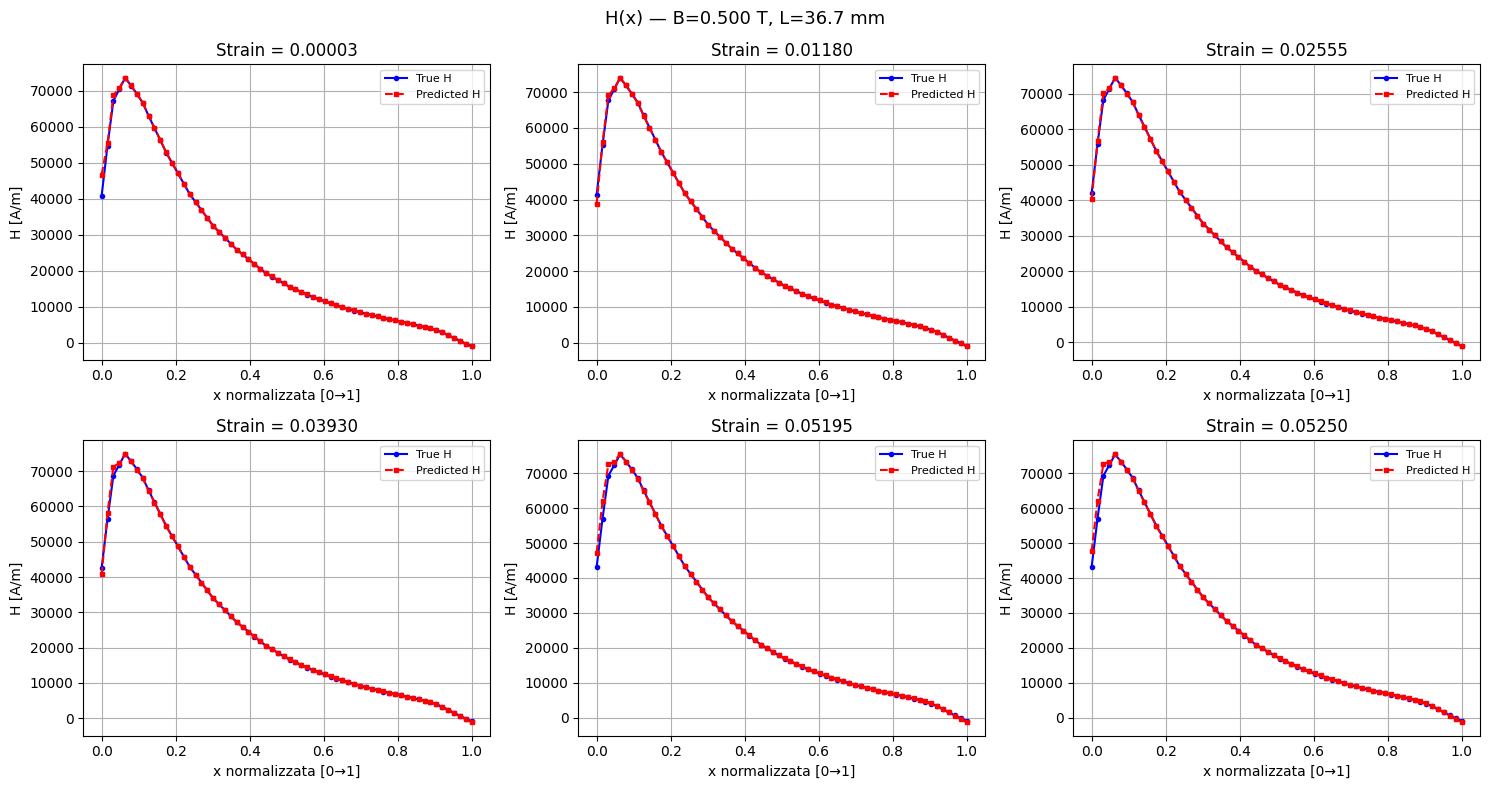

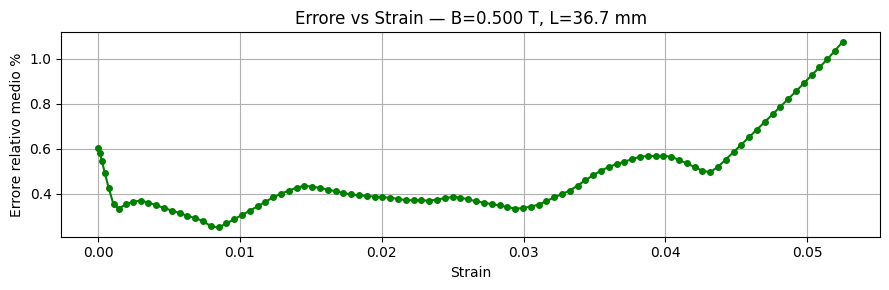

B=0.500 T, L=36.7 mm | Errore medio=0.47%  Max=1.08%


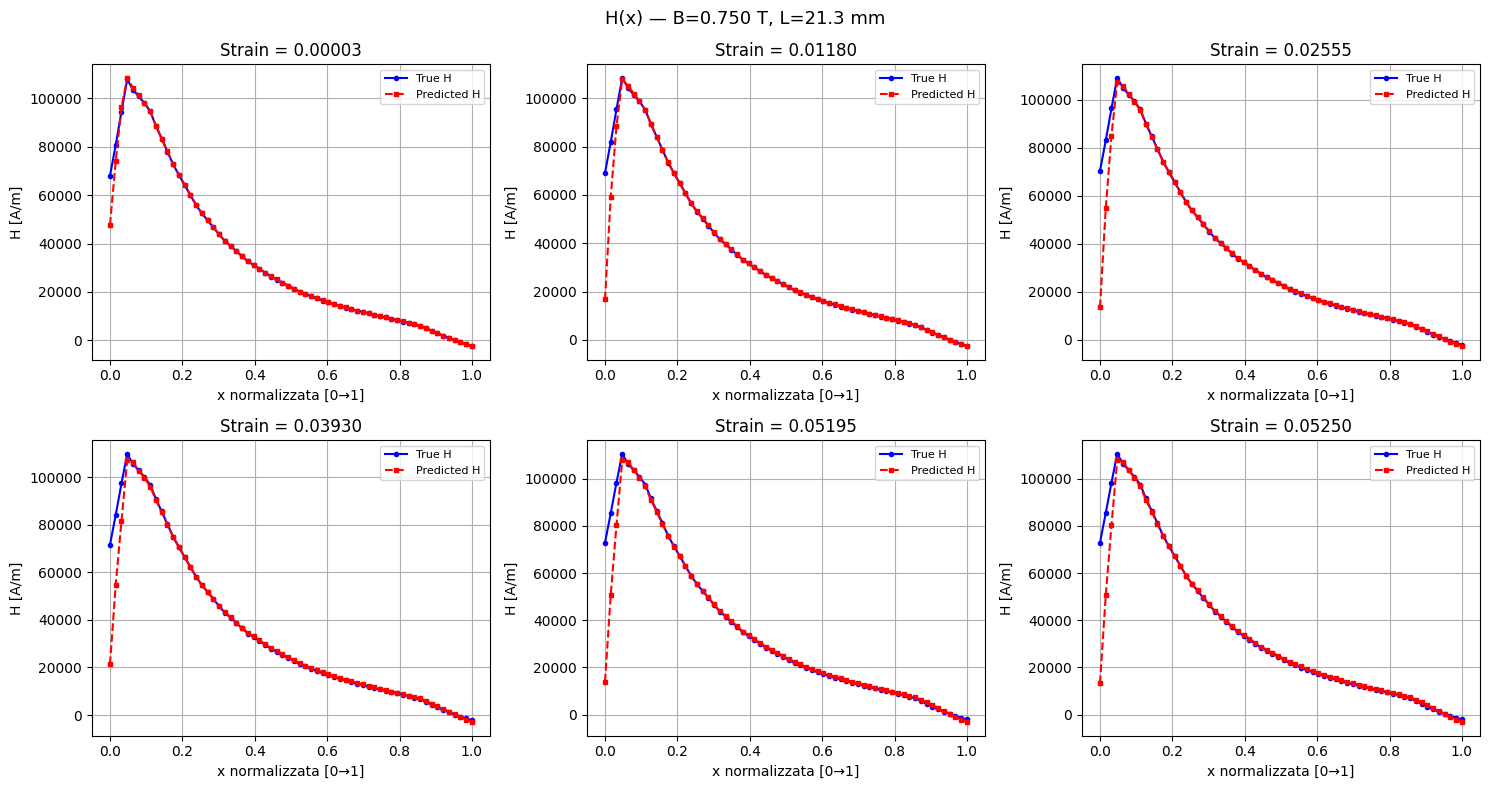

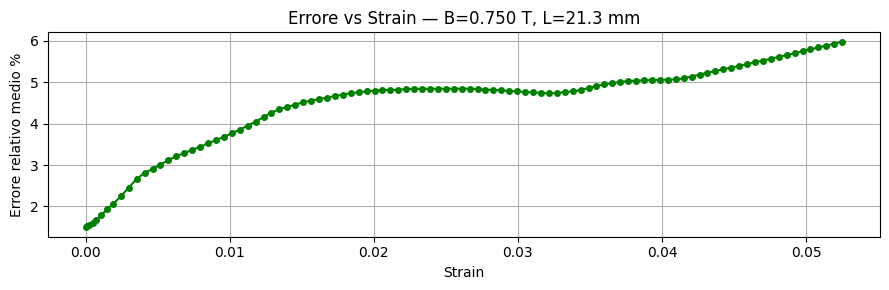

B=0.750 T, L=21.3 mm | Errore medio=4.42%  Max=5.98%


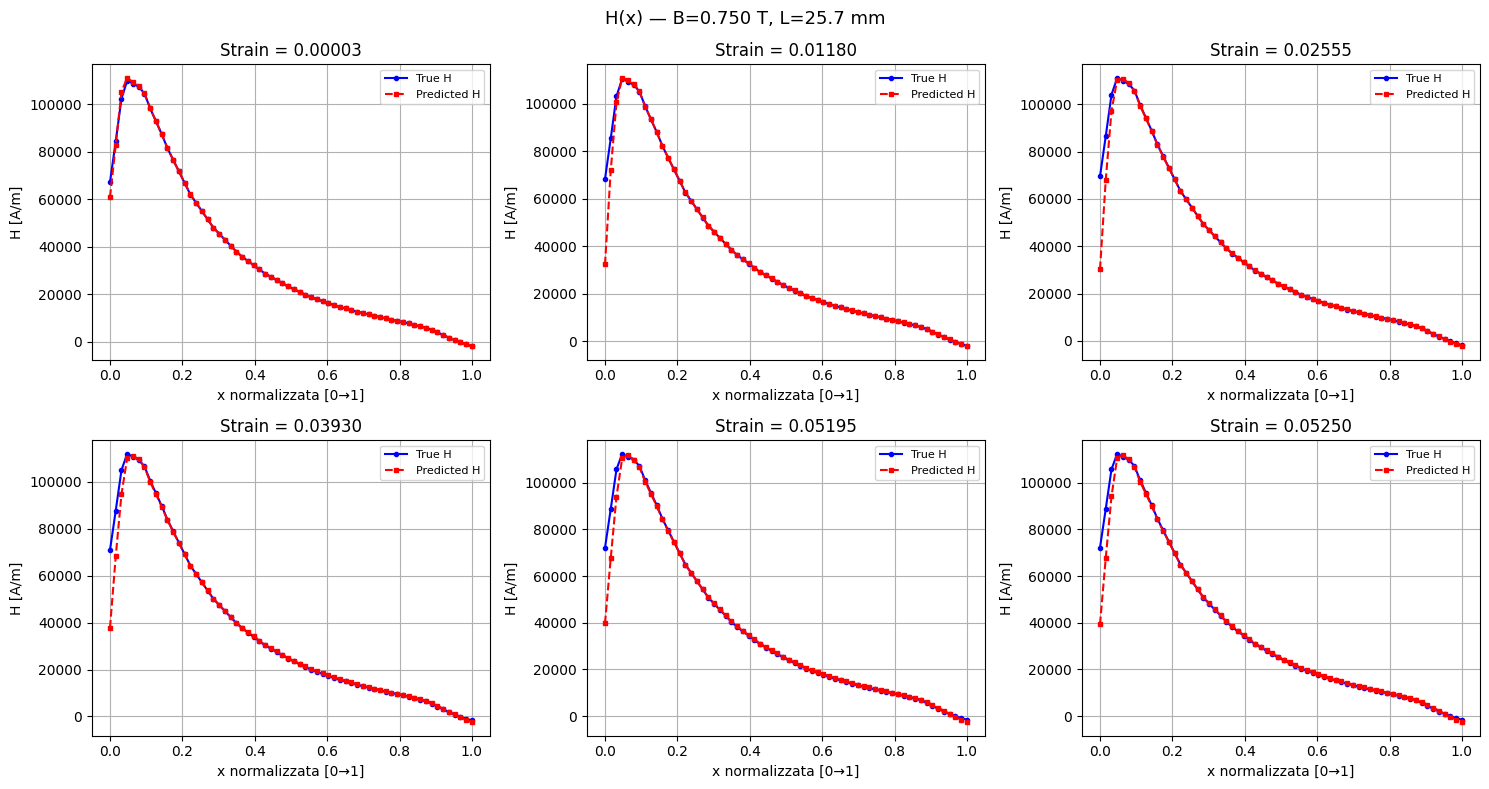

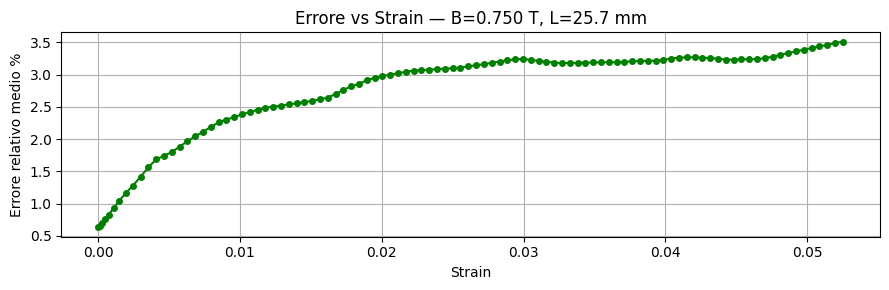

B=0.750 T, L=25.7 mm | Errore medio=2.74%  Max=3.51%


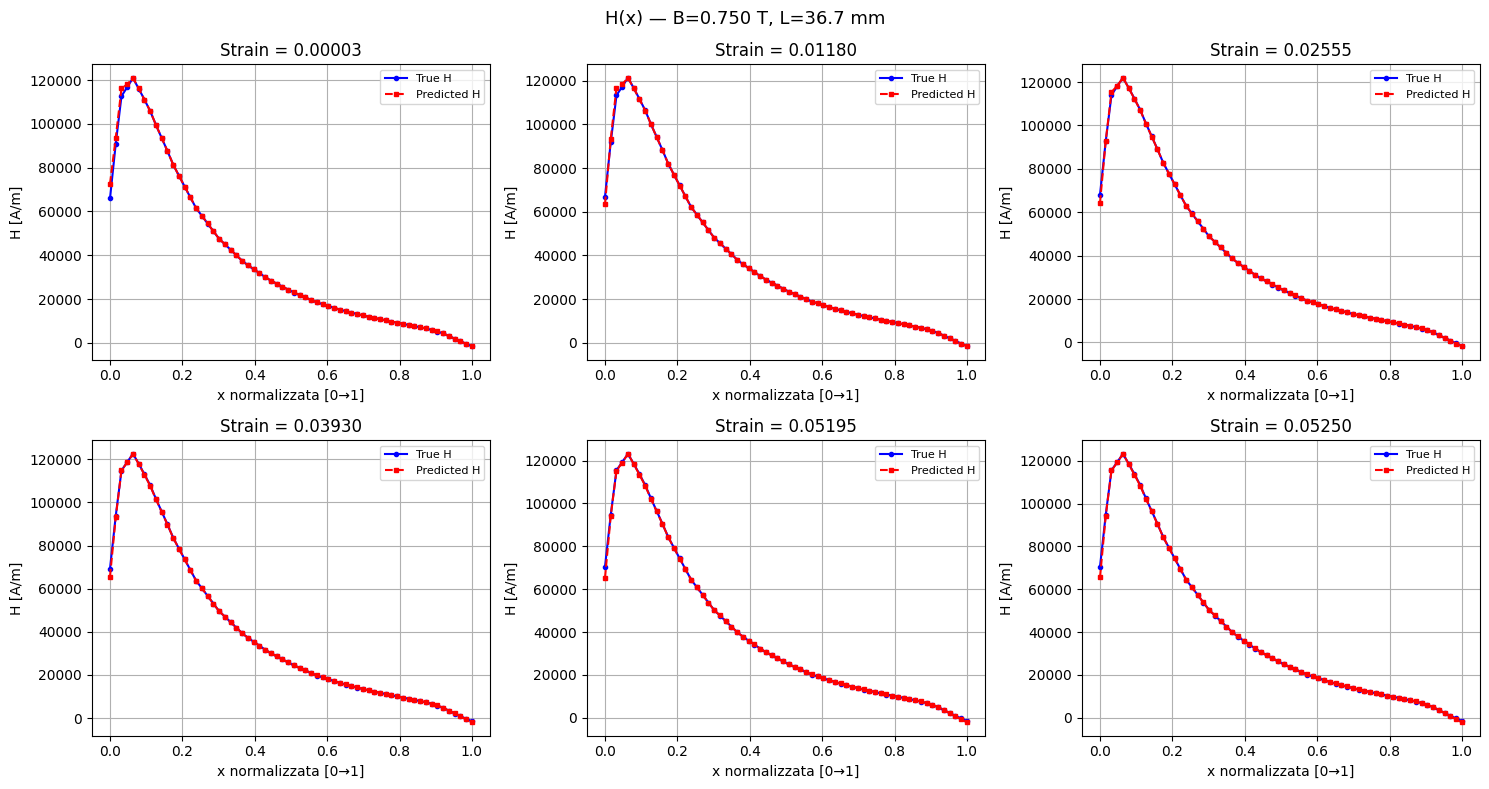

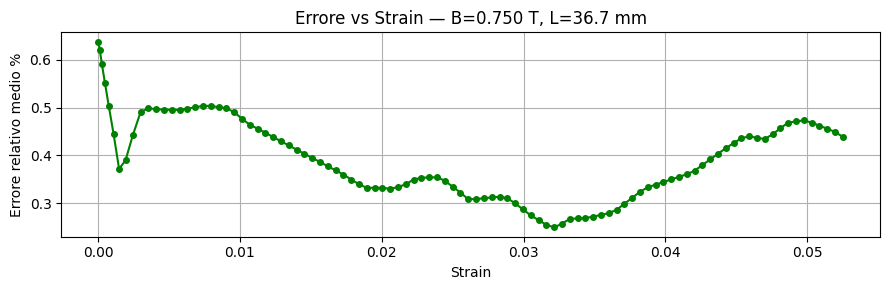

B=0.750 T, L=36.7 mm | Errore medio=0.39%  Max=0.64%


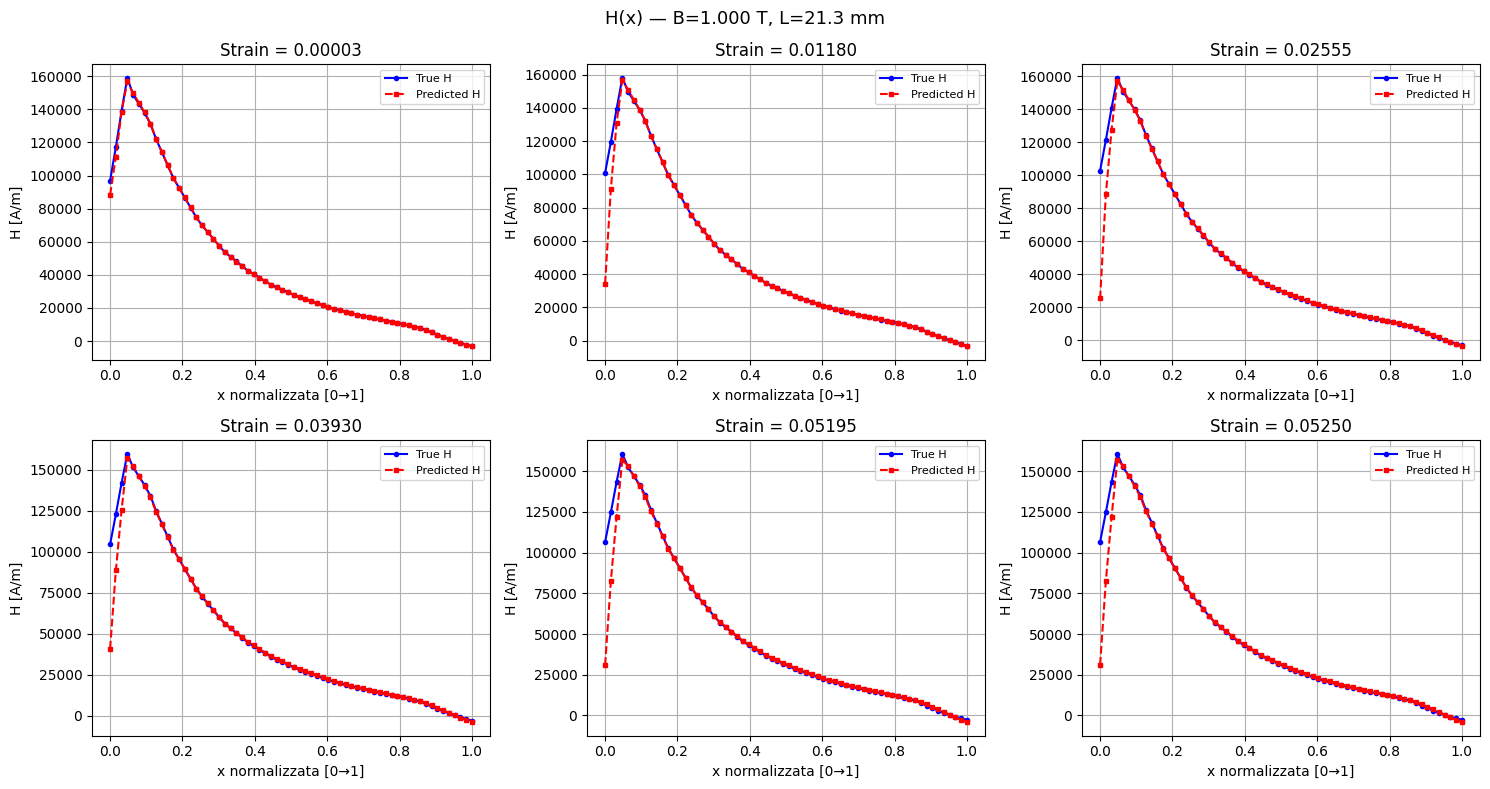

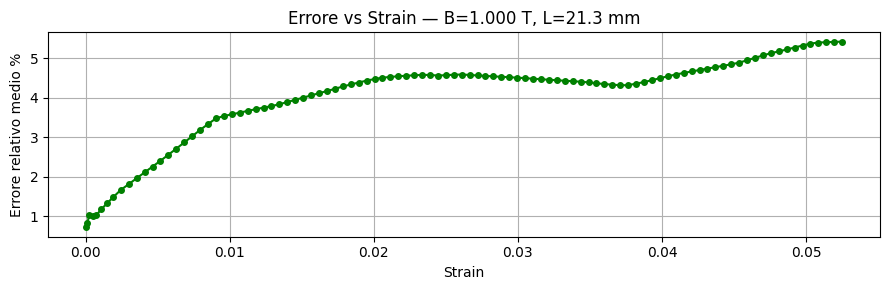

B=1.000 T, L=21.3 mm | Errore medio=3.98%  Max=5.42%


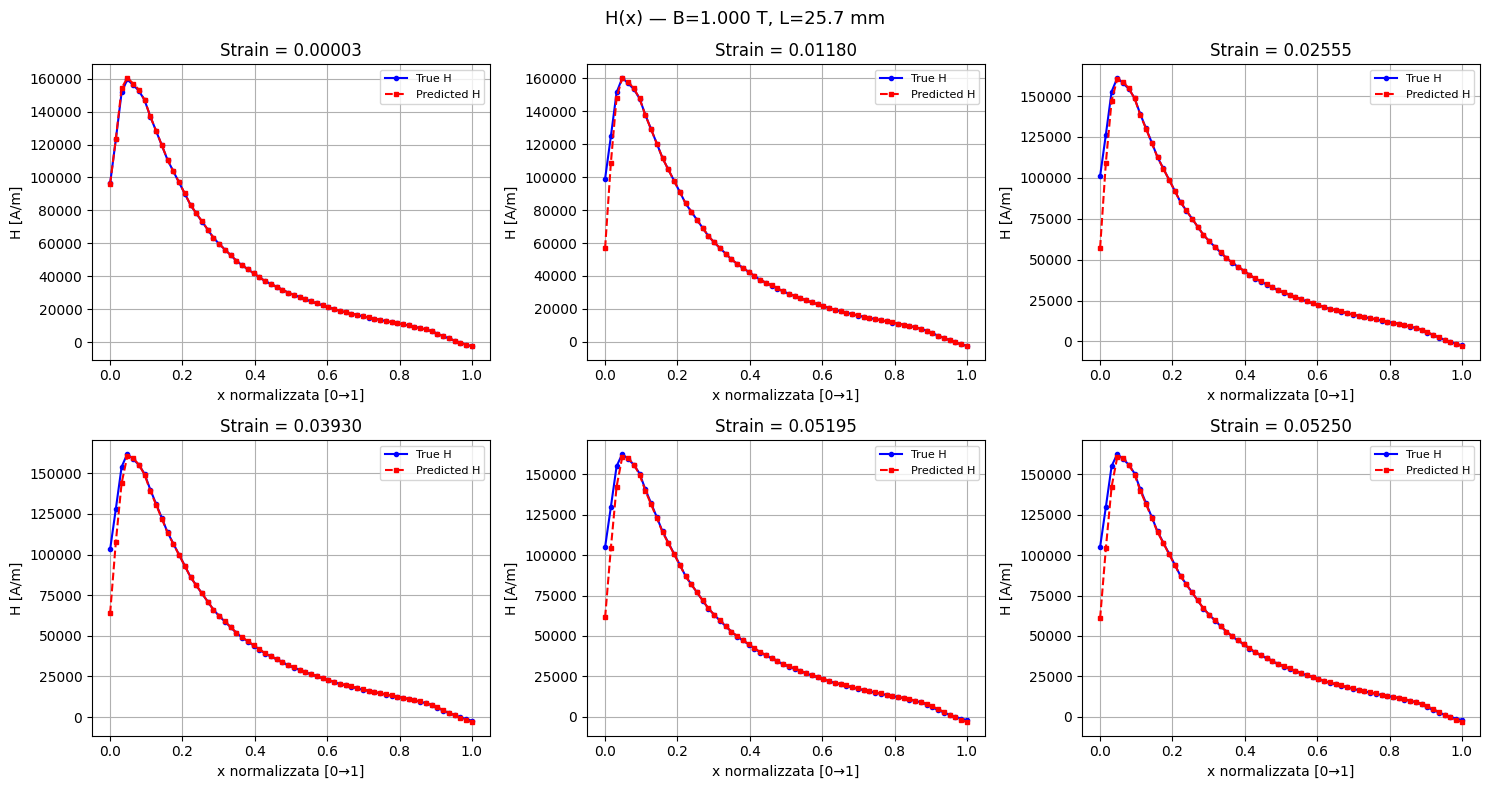

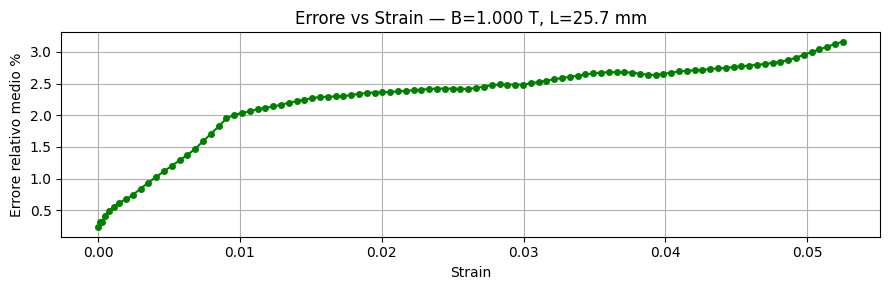

B=1.000 T, L=25.7 mm | Errore medio=2.22%  Max=3.16%


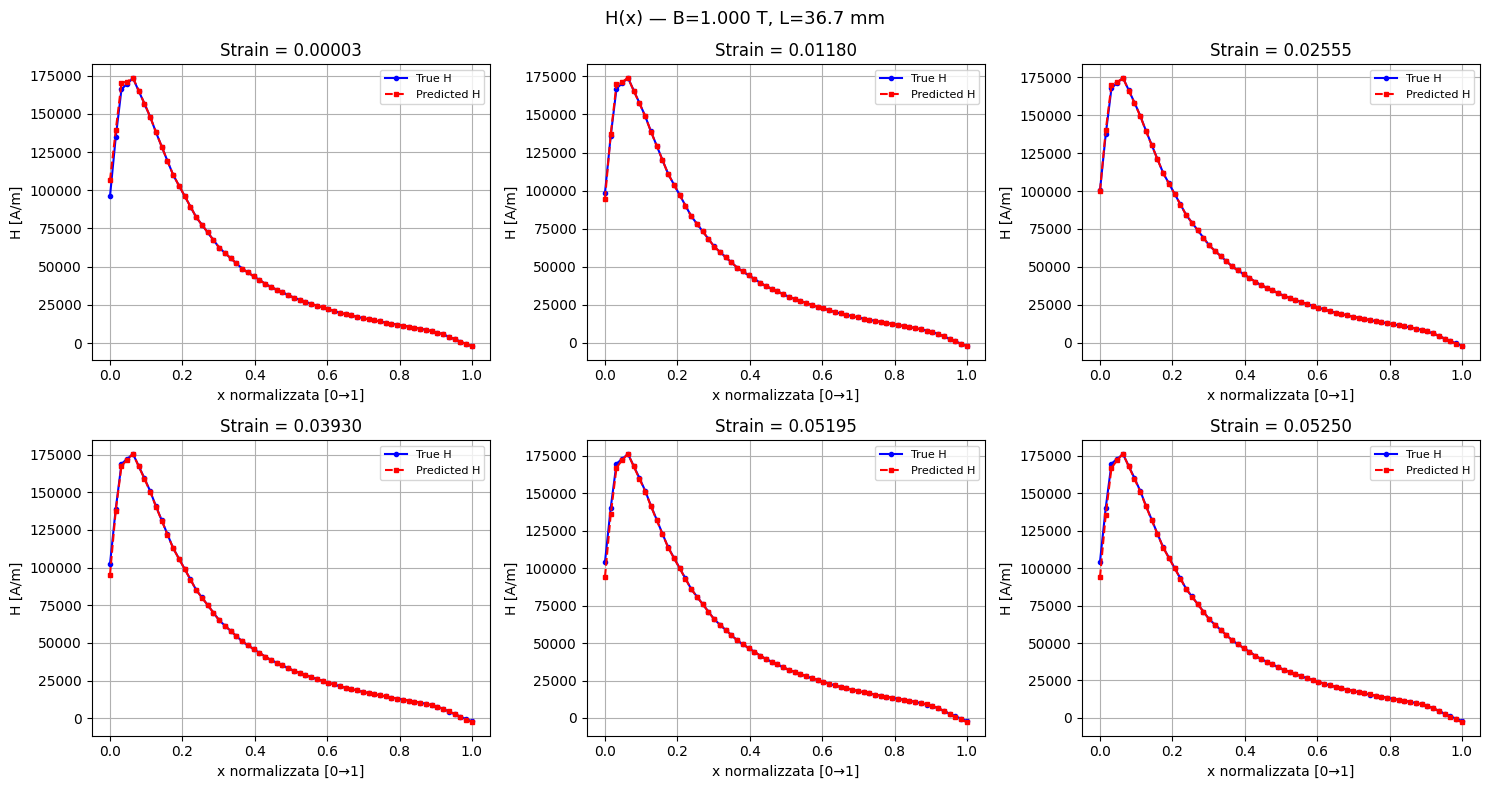

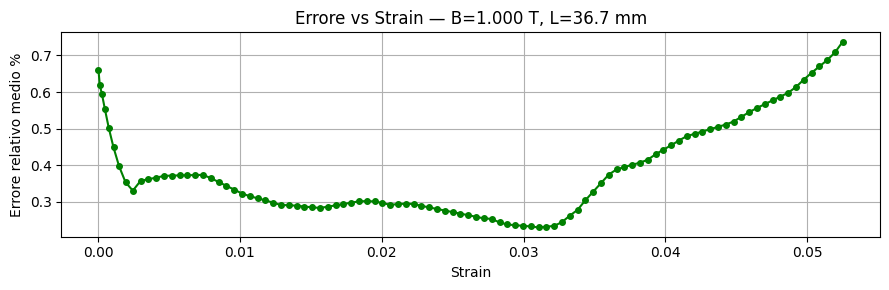

B=1.000 T, L=36.7 mm | Errore medio=0.39%  Max=0.74%


In [435]:
# ================================================================
# LOOP PRINCIPALE: per ogni coppia, H_init = primo snapshot,
# predici dH per tutti gli strain successivi, ricostruisci H
# ================================================================

fig_idx = 0  # contatore per scegliere quali coppie plottare

for (b_val, l_val), snapshots in coppie_dict.items():

    if len(snapshots) < 2:
        continue  # serve almeno un passo target

    L_in_metri = l_val / 1000.0

    # --- H iniziale (primo snapshot) interpolato su griglia fissa ---
    s0, _, data0 = snapshots[0]
    x0_norm = data0['X'].values / L_in_metri
    H0_raw  = data0['H'].values

    #interp0 = interp1d(x0_norm, H0_raw, kind='linear', fill_value='extrapolate')
    interp0 = PchipInterpolator(x0_norm, H0_raw)
    H_init_fixed = interp0(x_fixed)   # (64,)


    strain_list  = []
    H_pred_list  = []
    H_true_list  = []

    for s_val, nome_curva, input_data in snapshots[1:]:

        # H_true di questo snapshot interpolato su griglia fissa
        x_t_norm   = input_data['X'].values / L_in_metri
        H_t_raw    = input_data['H'].values
        # interp_t   = interp1d(x_t_norm, H_t_raw, kind='linear', fill_value='extrapolate')
        interp_t = PchipInterpolator(x_t_norm, H_t_raw)
        H_true_fixed = interp_t(x_fixed)   # (64,)

        # Costruisci input (1, 67): [B, L, strain, H_init(64)]
        x_input = np.concatenate([
            np.array([[b_val, l_val, s_val]]),
            H_init_fixed.reshape(1, -1)
        ], axis=1)

        x_input_sc = scaler_X.transform(x_input)
        x_tensor   = torch.tensor(x_input_sc, dtype=torch.float32)

        with torch.no_grad():
            dH_pred_sc = model(x_tensor).numpy()   # (1, 64)

        dH_pred      = scaler_y.inverse_transform(dH_pred_sc).flatten()
        H_pred_fixed = H_init_fixed + dH_pred      # (64,) — H assoluto predetto

        strain_list.append(s_val)
        H_pred_list.append(H_pred_fixed)
        H_true_list.append(H_true_fixed)

        # Errore relativo per questo snapshot
        err_abs  = np.abs(H_pred_fixed - H_true_fixed)
        mean_err = (np.sum(err_abs) / (np.sum(np.abs(H_true_fixed)) + 1e-6)) * 100
        ERR_MN.append(mean_err)
        PAIR.append((b_val, l_val))

    # Converti in matrici (n_strain, 64)
    H_pred_mat   = np.array(H_pred_list)
    H_true_mat   = np.array(H_true_list)
    strain_array = np.array(strain_list)

    # ---- Plot 6 istanti di strain per questa coppia ----
    n_steps = len(strain_array)
    t_da_plottare = [0,
                     n_steps // 4,
                     n_steps // 2,
                     3 * n_steps // 4,
                     -2, -1]
    # Evita duplicati se n_steps è piccolo
    t_da_plottare = sorted(set([max(0, min(t % n_steps, n_steps-1))
                                for t in t_da_plottare]))

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, t_idx in zip(axes.flatten(), t_da_plottare):
        ax.plot(x_fixed, H_true_mat[t_idx], 'b-o',  label='True H',      markersize=3)
        ax.plot(x_fixed, H_pred_mat[t_idx], 'r--s', label='Predicted H', markersize=3)
        ax.set_title(f'Strain = {strain_array[t_idx]:.5f}')
        ax.set_xlabel('x normalizzata [0→1]')
        ax.set_ylabel('H [A/m]')
        ax.legend(fontsize=8)
        ax.grid(True)

    plt.suptitle(f'H(x) — B={b_val:.3f} T, L={l_val:.1f} mm', fontsize=13)
    plt.tight_layout()
    plt.show()

    # ---- Errore relativo vs strain ----
    err_per_strain = (np.mean(np.abs(H_pred_mat - H_true_mat), axis=1) /
                      (np.mean(np.abs(H_true_mat), axis=1) + 1e-4)) * 100

    plt.figure(figsize=(9, 3))
    plt.plot(strain_array, err_per_strain, 'g-o', markersize=4)
    plt.xlabel('Strain')
    plt.ylabel('Errore relativo medio %')
    plt.title(f'Errore vs Strain — B={b_val:.3f} T, L={l_val:.1f} mm')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print(f"B={b_val:.3f} T, L={l_val:.1f} mm | "
          f"Errore medio={np.mean(err_per_strain):.2f}%  "
          f"Max={np.max(err_per_strain):.2f}%")

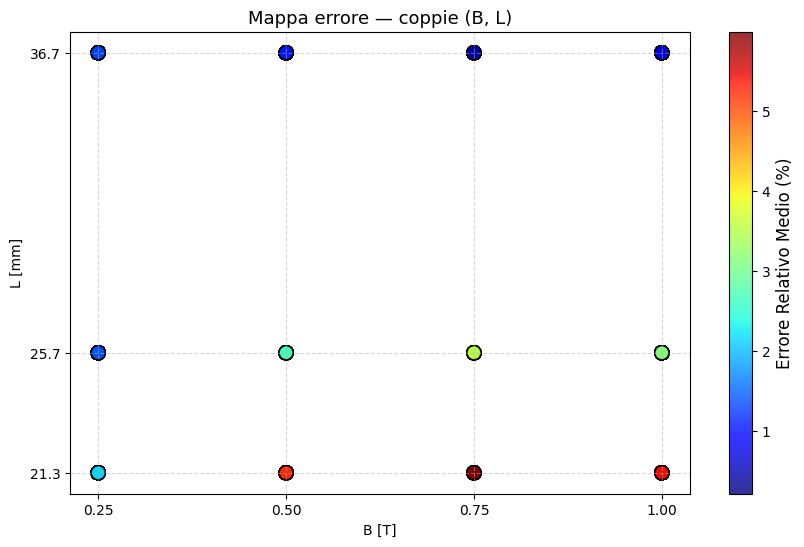

Errore medio globale: 2.01%
Errore max:           5.98%


In [436]:
# ================================================================
# MAPPA ERRORE GLOBALE SU SPAZIO (B, L)  — invariata
# ================================================================
err_array  = np.array(ERR_MN)
pair_array = np.array(PAIR)
b_valori   = pair_array[:, 0]
l_valori   = pair_array[:, 1]

plt.figure(figsize=(10, 6))
scatter = plt.scatter(b_valori, l_valori, c=err_array, cmap='jet',
                      s=100, edgecolors='k', alpha=0.8)
cbar = plt.colorbar(scatter)
cbar.set_label('Errore Relativo Medio (%)', fontsize=12)
plt.title('Mappa errore — coppie (B, L)', fontsize=13)
plt.xlabel('B [T]')
plt.ylabel('L [mm]')
plt.xticks(np.unique(b_valori))
plt.yticks(np.unique(l_valori))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Errore medio globale: {np.mean(err_array):.2f}%")
print(f"Errore max:           {np.max(err_array):.2f}%")

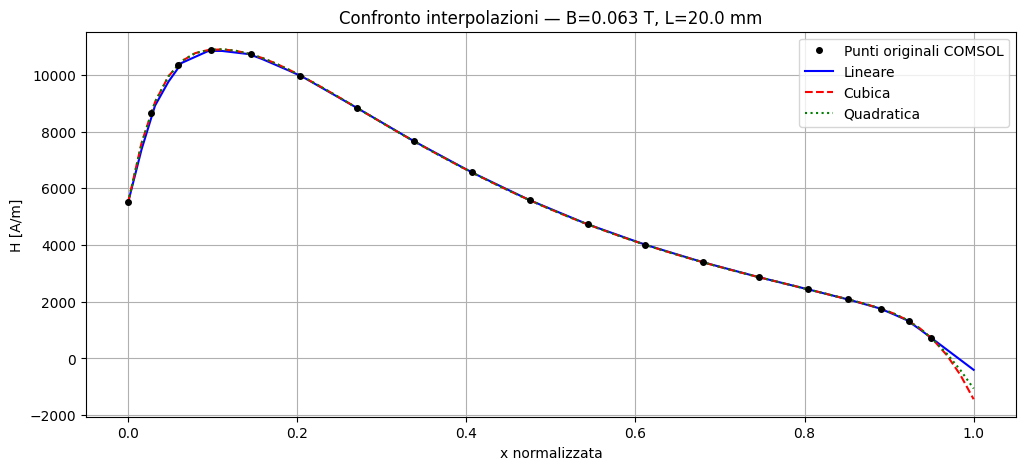

In [437]:
from scipy.interpolate import interp1d

# Prendi una curva qualsiasi dal dataset
(B, L), gruppo = next(iter(df_new.groupby(['B_magn_T', 'TPU_L_mm'])))
step0 = gruppo[gruppo['Strain_target'] == sorted(gruppo['Strain_target'].unique())[0]]
step0 = step0.sort_values('x_coord_m')

x0 = step0['x_norm'].values
H0 = step0['H_true'].values

x_fixed = np.linspace(0, 1, 64)

interp_lin   = interp1d(x0, H0, kind='linear',   fill_value='extrapolate')
interp_cub   = interp1d(x0, H0, kind='cubic',    fill_value='extrapolate')
interp_pchip = interp1d(x0, H0, kind='quadratic',fill_value='extrapolate')

plt.figure(figsize=(12, 5))
plt.plot(x0, H0, 'ko', markersize=4, label='Punti originali COMSOL', zorder=5)
plt.plot(x_fixed, interp_lin(x_fixed),   'b-',  label='Lineare')
plt.plot(x_fixed, interp_cub(x_fixed),   'r--', label='Cubica')
plt.plot(x_fixed, interp_pchip(x_fixed), 'g:',  label='Quadratica')
plt.xlabel('x normalizzata')
plt.ylabel('H [A/m]')
plt.title(f'Confronto interpolazioni — B={B:.3f} T, L={L:.1f} mm')
plt.legend()
plt.grid(True)
plt.show()